# Sumativa 3: Modelamiento predictivo integrado de rotación de personal

**Asignatura:** Estadística Computacional  
**Integrantes:** Hernán Saavedra, Lenin Morales y Rodrigo Gómez  
**Dataset:** IBM HR Employee Attrition  
**Repositorio:** https://github.com/hernansaavedrag/estadisticaComputacional

## Propósito e integración

El proyecto conecta la exploración e inferencia de S1, la validación
mediante remuestreo de S2 y el modelamiento predictivo de S3.

Se reutilizan los 147 ingresos ocultados mediante MCAR en Formativa 2
y su partición 70/30 estratificada por Attrition. El dataset original
de S1 y S2 no tenía faltantes.

Se comparan tres estrategias de faltantes, tres modelos logísticos
y M2c, variante motivada por los diagnósticos. Se evalúan ponderación,
desempeño, estabilidad bootstrap y sensibilidad a la imputación.

## Ejecución reproducible

Ejecutar todas las celdas en orden desde la raíz del repositorio o
desde S3/notebooks, utilizando las dependencias de S3/requirements.txt.

Se requieren los datos e insumos previos del repositorio y las funciones
de S3/src. El bootstrap utiliza procesos independientes y lotes
reanudables: si los 10.000 intentos ya existen y corresponden a la
configuración actual, se recuperan sin repetirlos.

El ajuste y las transformaciones utilizan entrenamiento. La elección
de variables y transformaciones introduce incertidumbre que no queda
completamente incorporada en los intervalos finales.

Los datos son sintéticos. Los resultados son exploratorios y no
demuestran causalidad ni justifican políticas reales de personal.


# Parte 1. Preparación e imputación


In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from sklearn.impute import SimpleImputer

SEMILLA = 42

RAIZ = next(
    (
        carpeta
        for carpeta in [Path.cwd(), *Path.cwd().parents]
        if (
            carpeta / "datos" / "WA_Fn-UseC_-HR-Employee-Attrition.csv"
        ).is_file()
    ),
    None,
)

if RAIZ is None:
    raise FileNotFoundError("No se encontró la raíz del repositorio.")

DIRECTORIO_F2 = RAIZ / "Formativa2"
DIRECTORIO_S2 = RAIZ / "S2"
DIRECTORIO_S3 = RAIZ / "S3"

for nombre in ["datos", "resultados", "figuras", "docs"]:
    (DIRECTORIO_S3 / nombre).mkdir(parents=True, exist_ok=True)

archivos_requeridos = [
    DIRECTORIO_F2 / "datos" / "IBM_HR_MCAR.csv",
    DIRECTORIO_F2 / "datos" / "valores_ocultados_ingreso.csv",
    DIRECTORIO_F2 / "datos" / "particion_70_30.csv",
    DIRECTORIO_S2 / "resultados" / "S2_reporte_validado_S3.json",
]

for ruta in archivos_requeridos:
    if not ruta.is_file():
        raise FileNotFoundError(
            f"Falta un insumo previo: {ruta.relative_to(RAIZ)}"
        )

print("Python:", sys.version.split()[0])
print("Insumos de F2 y S2 encontrados.")
print("Entorno preparado para Sumativa 3.")

Python: 3.14.2
Insumos de F2 y S2 encontrados.
Entorno preparado para Sumativa 3.


## 1. Recuperación de datos y partición de Formativa 2

Se carga la versión MCAR guardada en F2 y se comprueba que únicamente
MonthlyIncome presenta faltantes. Se verifican los identificadores y
el respaldo contra el dataset original.

La asignación a entrenamiento y prueba se recupera del archivo de
partición. El dataset original y los valores ocultados se mantienen
separados de los datos empleados para ajustar la imputación.

In [2]:
df_original = pd.read_csv(
    RAIZ / "datos" / "WA_Fn-UseC_-HR-Employee-Attrition.csv"
).set_index("EmployeeNumber")

df_mcar = pd.read_csv(
    DIRECTORIO_F2 / "datos" / "IBM_HR_MCAR.csv"
).set_index("EmployeeNumber")

valores_ocultados = pd.read_csv(
    DIRECTORIO_F2 / "datos" / "valores_ocultados_ingreso.csv"
).set_index("EmployeeNumber")

particion = pd.read_csv(
    DIRECTORIO_F2 / "datos" / "particion_70_30.csv"
).set_index("EmployeeNumber")

reporte_s2 = json.loads(
    (
        DIRECTORIO_S2 / "resultados" / "S2_reporte_validado_S3.json"
    ).read_text(encoding="utf-8")
)

# Verificar que se conserva la versión MCAR de F2.
assert df_mcar.index.is_unique
assert valores_ocultados.index.is_unique
assert particion.index.is_unique
assert set(particion.index) == set(df_mcar.index)
assert set(particion["Conjunto"]) == {"Entrenamiento", "Prueba"}

assert df_mcar["MonthlyIncome"].isna().sum() == 147
assert df_mcar.isna().sum().sum() == 147

ids_ocultados = df_mcar.index[df_mcar["MonthlyIncome"].isna()]
assert set(ids_ocultados) == set(valores_ocultados.index)

pd.testing.assert_frame_equal(
    df_mcar.drop(columns="MonthlyIncome"),
    df_original.drop(columns="MonthlyIncome"),
)

np.testing.assert_allclose(
    valores_ocultados["MonthlyIncome"],
    df_original.loc[valores_ocultados.index, "MonthlyIncome"],
)

# Recuperar la asignación existente, sin sortear otra partición.
train = df_mcar.loc[
    particion.index[particion["Conjunto"] == "Entrenamiento"]
].copy()

test = df_mcar.loc[
    particion.index[particion["Conjunto"] == "Prueba"]
].copy()

assert len(train) == 1029 and len(test) == 441
assert set(train.index).isdisjoint(test.index)

resumen_datos = pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Prueba"],
    "Registros": [len(train), len(test)],
    "Ingresos faltantes": [
        train["MonthlyIncome"].isna().sum(),
        test["MonthlyIncome"].isna().sum(),
    ],
    "Salidas": [
        train["Attrition"].eq("Yes").sum(),
        test["Attrition"].eq("Yes").sum(),
    ],
})

display(resumen_datos)
print("Partición de F2 recuperada y respaldo verificado.")
print("Reporte de resultados validados de S2 cargado.")

,Conjunto,Registros,Ingresos faltantes,Salidas
0,Entrenamiento,1029,96,166
1,Prueba,441,51,71


Partición de F2 recuperada y respaldo verificado.
Reporte de resultados validados de S2 cargado.


## 2. Predictores para la imputación del ingreso

Se seleccionan tres variables numéricas disponibles sin faltantes:

| Predictor | Fundamento |
|-----------|------------|
| TotalWorkingYears | En S2, su correlación de Spearman con MonthlyIncome fue aproximadamente 0,710, con IC bootstrap BCa del 95 % [0,679; 0,739]. |
| Age | En S1 se observó una relación positiva con ingreso. Su relación con experiencia laboral fue validada en S2. |
| YearsAtCompany | En S1 se observó una relación positiva con ingreso. Su relación con experiencia laboral también fue validada en S2. |

Los intervalos de S2 respaldan relaciones específicas entre variables;
no implican que todas las correlaciones con ingreso hayan sido validadas.

Como los tres predictores están relacionados, se revisará su VIF antes
de interpretar la regresión. La utilidad para imputar se evaluará con
predicciones y diagnósticos, no únicamente mediante correlaciones.

MonthlyIncome será la respuesta de la regresión lineal. Attrition y
EmployeeNumber no se utilizarán como predictores. El ajuste empleará
solo registros de entrenamiento con ingreso observado.

In [3]:
PREDICTORES_IMPUTACION = [
    "TotalWorkingYears",
    "Age",
    "YearsAtCompany",
]

# Para ajustar la imputación, usar exclusivamente ingresos observados
# del entrenamiento y predictores completos.
train_observado = train.dropna(
    subset=["MonthlyIncome", *PREDICTORES_IMPUTACION]
).copy()

assert train[PREDICTORES_IMPUTACION].notna().all().all()
assert test[PREDICTORES_IMPUTACION].notna().all().all()
assert len(train_observado) == 933

X_imputacion = train_observado[PREDICTORES_IMPUTACION].astype(float)
y_imputacion = train_observado["MonthlyIncome"].astype(float)

print("Predictores:", PREDICTORES_IMPUTACION)
print("Registros disponibles para ajustar:", len(train_observado))
print("Ingresos por imputar en entrenamiento:",
      train["MonthlyIncome"].isna().sum())
print("Ingresos por imputar en prueba:",
      test["MonthlyIncome"].isna().sum())

print("\nCorrelaciones de Pearson en entrenamiento observado:")
display(
    train_observado[
        ["MonthlyIncome", *PREDICTORES_IMPUTACION]
    ].corr().round(3)
)

Predictores: ['TotalWorkingYears', 'Age', 'YearsAtCompany']
Registros disponibles para ajustar: 933
Ingresos por imputar en entrenamiento: 96
Ingresos por imputar en prueba: 51

Correlaciones de Pearson en entrenamiento observado:


,MonthlyIncome,TotalWorkingYears,Age,YearsAtCompany
MonthlyIncome,1.000,0.776,0.514,0.496
TotalWorkingYears,0.776,1.000,0.686,0.615
Age,0.514,0.686,1.000,0.299
YearsAtCompany,0.496,0.615,0.299,1.000


## 3. Ajuste de la regresión lineal múltiple

Se estima MonthlyIncome mediante experiencia laboral total, edad y
antigüedad en la empresa, incluyendo intercepto. El ajuste utiliza
exclusivamente los 933 registros de entrenamiento con ingreso observado.

Se calcula el VIF para evaluar la redundancia entre predictores.
Los coeficientes expresan asociaciones ajustadas con el ingreso y
no representan efectos causales.

El resumen del ajuste describe el comportamiento dentro de estos
registros. Posteriormente se evaluarán los residuos y el error
predictivo antes de utilizar el modelo para imputar.

In [4]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_imputacion_const = sm.add_constant(
    X_imputacion,
    has_constant="add",
)

# Calcular VIF con intercepto, pero mostrar solo los predictores.
matriz_vif = X_imputacion_const.to_numpy(dtype=float)

vif_imputacion = pd.DataFrame({
    "Variable": X_imputacion_const.columns,
    "VIF": [
        variance_inflation_factor(matriz_vif, i)
        for i in range(matriz_vif.shape[1])
    ],
})

vif_imputacion = vif_imputacion.loc[
    vif_imputacion["Variable"] != "const"
].reset_index(drop=True)

display(vif_imputacion.round(3))

# Ajustar por mínimos cuadrados ordinarios.
modelo_ingreso = sm.OLS(
    y_imputacion,
    X_imputacion_const,
).fit()

print(modelo_ingreso.summary())

vif_imputacion.to_csv(
    DIRECTORIO_S3 / "resultados" / "hernan_imputacion_vif.csv",
    index=False,
)

tabla_coeficientes_ingreso = pd.DataFrame({
    "Coeficiente": modelo_ingreso.params,
    "Error estandar": modelo_ingreso.bse,
    "Valor p": modelo_ingreso.pvalues,
    "IC95 inferior": modelo_ingreso.conf_int()[0],
    "IC95 superior": modelo_ingreso.conf_int()[1],
})

tabla_coeficientes_ingreso.to_csv(
    DIRECTORIO_S3 / "resultados" / "hernan_imputacion_coeficientes.csv",
    index_label="Termino",
)

print("\nResultados del ajuste guardados.")

,Variable,VIF
0,TotalWorkingYears,2.897
1,Age,1.980
2,YearsAtCompany,1.684


                            OLS Regression Results                            
Dep. Variable:          MonthlyIncome   R-squared:                       0.604
Model:                            OLS   Adj. R-squared:                  0.603
Method:                 Least Squares   F-statistic:                     472.1
Date:                Sun, 25 Oct 2026   Prob (F-statistic):          2.90e-186
Time:                        16:06:08   Log-Likelihood:                -8761.0
No. Observations:                 933   AIC:                         1.753e+04
Df Residuals:                     929   BIC:                         1.755e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const              1673.1323    445.95

## 4. Diagnóstico de residuos

Se examinan residuos frente a valores ajustados para detectar patrones
de falta de linealidad o cambios de dispersión, y un gráfico Q-Q para
examinar desviaciones respecto de la normalidad.

La prueba de Breusch-Pagan complementa la evaluación de
heterocedasticidad. Su hipótesis nula es varianza constante de los
errores, bajo las condiciones de la prueba.

La normalidad de los errores no es necesaria para calcular predicciones
por mínimos cuadrados, pero sus desviaciones y la heterocedasticidad
afectan la interpretación de la inferencia clásica. Estos diagnósticos
no sustituyen la evaluación del error predictivo.

La independencia no puede confirmarse únicamente con los residuos:
se mantiene como supuesto de trabajo para estos registros sintéticos.

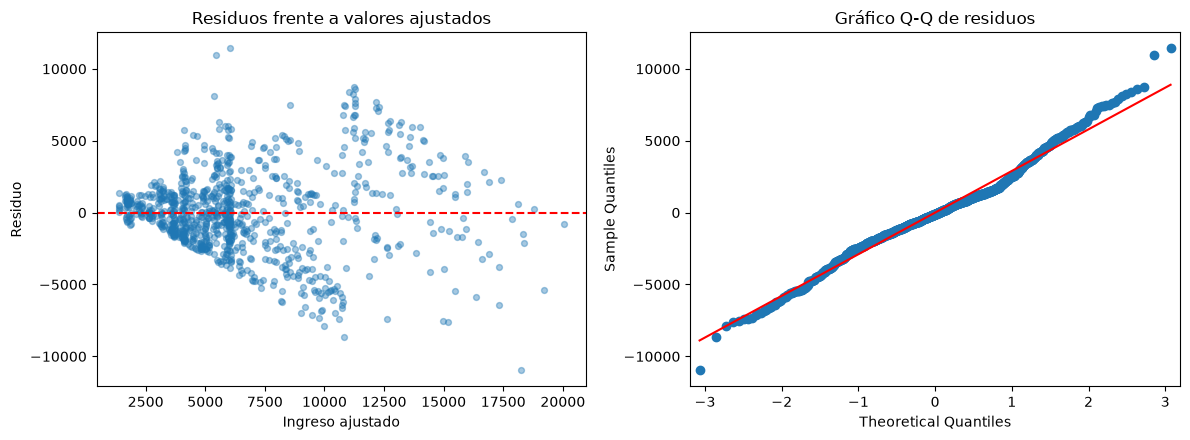

,Prueba,Estadistico LM,Valor p LM,Estadistico F,Valor p F
0,Breusch-Pagan,183.909784,1.262068e-39,76.02653,5.579882e-44


Ingresos ajustados negativos: 0


In [5]:
from statsmodels.stats.diagnostic import het_breuschpagan

ajustados = modelo_ingreso.fittedvalues
residuos = modelo_ingreso.resid

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].scatter(ajustados, residuos, alpha=0.4, s=18)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set(
    xlabel="Ingreso ajustado",
    ylabel="Residuo",
    title="Residuos frente a valores ajustados",
)

sm.qqplot(residuos, line="s", ax=axes[1])
axes[1].set_title("Gráfico Q-Q de residuos")

fig.tight_layout()
fig.savefig(
    DIRECTORIO_S3 / "figuras" / "hernan_imputacion_residuos.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

lm, p_lm, estadistico_f, p_f = het_breuschpagan(
    residuos,
    X_imputacion_const,
)

diagnostico_bp = pd.DataFrame({
    "Prueba": ["Breusch-Pagan"],
    "Estadistico LM": [lm],
    "Valor p LM": [p_lm],
    "Estadistico F": [estadistico_f],
    "Valor p F": [p_f],
})

diagnostico_bp.to_csv(
    DIRECTORIO_S3 / "resultados" / "hernan_imputacion_breusch_pagan.csv",
    index=False,
)

display(diagnostico_bp)

print(
    "Ingresos ajustados negativos:",
    int((ajustados < 0).sum()),
)

## 5. Evaluación predictiva dentro del entrenamiento

La prueba de Breusch-Pagan aporta evidencia de heterocedasticidad.
Por ello, la inferencia clásica requiere cautela; se complementará
con errores estándar robustos.

Se compara la imputación por regresión con la mediana mediante
validación cruzada de cinco pliegues sobre los 933 registros de
entrenamiento con ingreso observado.

En cada pliegue, la regresión y la mediana se ajustan únicamente con
los otros cuatro pliegues. Se calculan MAE y RMSE sobre predicciones
fuera del ajuste. Valores menores indican menor error.

Los registros de prueba y los valores artificialmente ocultados no
intervienen en esta comparación.

In [6]:
from sklearn.model_selection import KFold

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=SEMILLA,
)

pred_cv_regresion = np.full(len(y_imputacion), np.nan)
pred_cv_mediana = np.full(len(y_imputacion), np.nan)

for indices_ajuste, indices_validacion in cv.split(X_imputacion):
    X_ajuste = X_imputacion.iloc[indices_ajuste]
    y_ajuste = y_imputacion.iloc[indices_ajuste]
    X_validacion = X_imputacion.iloc[indices_validacion]

    modelo_pliegue = sm.OLS(
        y_ajuste,
        sm.add_constant(X_ajuste, has_constant="add"),
    ).fit()

    pred_cv_regresion[indices_validacion] = modelo_pliegue.predict(
        sm.add_constant(X_validacion, has_constant="add")
    )

    pred_cv_mediana[indices_validacion] = y_ajuste.median()

assert np.isfinite(pred_cv_regresion).all()
assert np.isfinite(pred_cv_mediana).all()

comparacion_cv = []

for nombre, predicciones in [
    ("Mediana", pred_cv_mediana),
    ("Regresion", pred_cv_regresion),
]:
    errores = y_imputacion.to_numpy() - predicciones

    comparacion_cv.append({
        "Estrategia": nombre,
        "Registros evaluados": len(errores),
        "MAE": np.mean(np.abs(errores)),
        "RMSE": np.sqrt(np.mean(errores ** 2)),
    })

comparacion_cv = pd.DataFrame(comparacion_cv)

comparacion_cv.to_csv(
    DIRECTORIO_S3 / "resultados" / "hernan_imputacion_validacion_cruzada.csv",
    index=False,
)

pd.DataFrame({
    "Ingreso observado": y_imputacion,
    "Prediccion CV mediana": pred_cv_mediana,
    "Prediccion CV regresion": pred_cv_regresion,
}).to_csv(
    DIRECTORIO_S3 / "resultados" / "hernan_imputacion_predicciones_cv.csv",
    index_label="EmployeeNumber",
)

display(comparacion_cv.round(2))

,Estrategia,Registros evaluados,MAE,RMSE
0,Mediana,933,3308.30,4848.16
1,Regresion,933,2174.84,2923.40


## 6. Inferencia robusta y resultados de validación

En validación cruzada, la regresión obtuvo MAE de 2.174,84 y RMSE
de 2.923,40, frente a 3.308,30 y 4.848,16 de la mediana.
Esto representa reducciones aproximadas de 34,3 % y 39,7 %,
respectivamente, dentro del entrenamiento observado.

Dada la heterocedasticidad detectada, se calculan errores estándar
robustos HC3 e intervalos del 95 %. Este ajuste modifica la inferencia,
pero conserva los coeficientes y las predicciones de mínimos cuadrados.
No corrige posibles errores de especificación ni incorpora toda la
incertidumbre de la imputación.

In [7]:
resultado_hc3 = modelo_ingreso.get_robustcov_results(cov_type="HC3")
intervalos_hc3 = np.asarray(resultado_hc3.conf_int(alpha=0.05))

tabla_hc3 = pd.DataFrame({
    "Variable": modelo_ingreso.model.exog_names,
    "Coeficiente": np.asarray(resultado_hc3.params),
    "Error estandar HC3": np.asarray(resultado_hc3.bse),
    "Valor p HC3": np.asarray(resultado_hc3.pvalues),
    "IC95 inferior HC3": intervalos_hc3[:, 0],
    "IC95 superior HC3": intervalos_hc3[:, 1],
})

tabla_hc3.to_csv(
    DIRECTORIO_S3 / "resultados" / "hernan_imputacion_coeficientes_hc3.csv",
    index=False,
)

display(tabla_hc3.round(4))
print("Inferencia robusta HC3 calculada y guardada.")

,Variable,Coeficiente,Error estandar HC3,Valor p HC3,IC95 inferior HC3,IC95 superior HC3
0,const,1673.1323,367.7867,0.0000,951.3431,2394.9214
1,TotalWorkingYears,467.9710,27.2443,0.0000,414.5035,521.4385
2,Age,-15.3636,12.3724,0.2146,-39.6447,8.9175
3,YearsAtCompany,17.8908,30.1965,0.5537,-41.3706,77.1521


Inferencia robusta HC3 calculada y guardada.


## 7. Construcción de las tres estrategias de faltantes

Se conserva la asignación original de entrenamiento y prueba:

- **Eliminación:** se excluyen los registros con ingreso faltante.
- **Mediana:** se rellenan los faltantes de ambos conjuntos con la
  mediana del entrenamiento observado.
- **Regresión:** se rellenan los faltantes con predicciones del modelo
  ajustado exclusivamente sobre entrenamiento observado.

Los ingresos observados se conservan. No se utilizan los valores
ocultados ni Attrition para calcular las imputaciones. Se comprueba
que las predicciones de ingreso sean positivas antes de aplicarlas.

In [8]:
# 1. Eliminación.
train_eliminacion = train.dropna(subset=["MonthlyIncome"]).copy()
test_eliminacion = test.dropna(subset=["MonthlyIncome"]).copy()

# 2. Mediana: ajustar solo con entrenamiento.
imputador_mediana = SimpleImputer(strategy="median")

train_mediana = train.copy()
test_mediana = test.copy()

train_mediana["MonthlyIncome"] = imputador_mediana.fit_transform(
    train[["MonthlyIncome"]]
).ravel()

test_mediana["MonthlyIncome"] = imputador_mediana.transform(
    test[["MonthlyIncome"]]
).ravel()

# 3. Regresión: aplicar el modelo ya ajustado.
train_regresion = train.copy()
test_regresion = test.copy()

for datos in [train_regresion, test_regresion]:
    faltantes = datos["MonthlyIncome"].isna()

    if faltantes.any():
        X_faltantes = datos.loc[
            faltantes, PREDICTORES_IMPUTACION
        ].astype(float)

        predicciones = modelo_ingreso.predict(
            sm.add_constant(X_faltantes, has_constant="add")
        )

        if not np.isfinite(predicciones).all():
            raise ValueError("Se generaron predicciones no finitas.")

        if (predicciones <= 0).any():
            raise ValueError(
                "Hay ingresos predichos no positivos. "
                "Revisar el modelo antes de imputar."
            )

        datos.loc[faltantes, "MonthlyIncome"] = predicciones

estrategias = {
    "eliminacion": {
        "train": train_eliminacion,
        "test": test_eliminacion,
    },
    "mediana": {
        "train": train_mediana,
        "test": test_mediana,
    },
    "regresion": {
        "train": train_regresion,
        "test": test_regresion,
    },
}

resumen_estrategias = []

for nombre, conjuntos in estrategias.items():
    for conjunto, datos in conjuntos.items():
        assert not datos.isna().any().any()

        # Verificar que ningún ingreso observado fue modificado.
        base = train if conjunto == "train" else test
        ids_observados = base.index[base["MonthlyIncome"].notna()]

        np.testing.assert_allclose(
            datos.loc[ids_observados, "MonthlyIncome"],
            base.loc[ids_observados, "MonthlyIncome"],
        )

        datos.to_csv(
            DIRECTORIO_S3 / "datos" / f"{nombre}_{conjunto}.csv",
            index_label="EmployeeNumber",
        )

        resumen_estrategias.append({
            "Estrategia": nombre,
            "Conjunto": conjunto,
            "Registros": len(datos),
            "Ingresos faltantes": datos["MonthlyIncome"].isna().sum(),
        })

resumen_estrategias = pd.DataFrame(resumen_estrategias)

resumen_estrategias.to_csv(
    DIRECTORIO_S3 / "resultados" / "hernan_resumen_estrategias.csv",
    index=False,
)

display(resumen_estrategias)
print("Mediana utilizada:", float(imputador_mediana.statistics_[0]))

,Estrategia,Conjunto,Registros,Ingresos faltantes
0,eliminacion,train,933,0
1,eliminacion,test,390,0
2,mediana,train,1029,0
3,mediana,test,441,0
4,regresion,train,1029,0
5,regresion,test,441,0


Mediana utilizada: 5067.0


## 8. Error de imputación frente a los valores ocultados

Como los faltantes fueron generados artificialmente, se conocen los
ingresos verdaderos de los 147 registros afectados. Se calculan MAE,
RMSE y sesgo medio para mediana y regresión, separados por conjunto.

El sesgo se define como ingreso imputado menos ingreso verdadero.
Un valor positivo indica sobreestimación media y uno negativo,
subestimación.

La eliminación no produce valores imputados: su error de imputación
no aplica. Su impacto se evalúa mediante la pérdida de observaciones.

Los valores ocultados no participaron en el ajuste. La selección
metodológica se fundamentará en entrenamiento; los errores de prueba
se reservan para la evaluación final.

In [9]:
resultados_error = []
detalle_error = []

for nombre in ["mediana", "regresion"]:
    for conjunto in ["train", "test"]:
        datos = estrategias[nombre][conjunto]

        ids_evaluar = datos.index[
            datos.index.isin(valores_ocultados.index)
        ]

        verdaderos = valores_ocultados.loc[
            ids_evaluar, "MonthlyIncome"
        ].to_numpy()

        imputados = datos.loc[
            ids_evaluar, "MonthlyIncome"
        ].to_numpy()

        errores = imputados - verdaderos

        resultados_error.append({
            "Estrategia": nombre,
            "Conjunto": conjunto,
            "Valores evaluados": len(ids_evaluar),
            "MAE": np.mean(np.abs(errores)),
            "RMSE": np.sqrt(np.mean(errores ** 2)),
            "Sesgo medio": np.mean(errores),
        })

        detalle_error.append(pd.DataFrame({
            "EmployeeNumber": ids_evaluar,
            "Estrategia": nombre,
            "Conjunto": conjunto,
            "Ingreso verdadero": verdaderos,
            "Ingreso imputado": imputados,
            "Error": errores,
        }))

errores_imputacion = pd.DataFrame(resultados_error)

errores_imputacion.to_csv(
    DIRECTORIO_S3 / "resultados" / "hernan_error_imputacion.csv",
    index=False,
)

pd.concat(detalle_error, ignore_index=True).to_csv(
    DIRECTORIO_S3 / "resultados" / "hernan_error_imputacion_detalle.csv",
    index=False,
)

# Mostrar por ahora solo entrenamiento.
display(
    errores_imputacion.loc[
        errores_imputacion["Conjunto"] == "train"
    ].round(2)
)

print("Errores de ambos conjuntos guardados para el informe final.")

,Estrategia,Conjunto,Valores evaluados,MAE,RMSE,Sesgo medio
0,mediana,train,96,3322.04,4859.04,-1317.79
2,regresion,train,96,2260.28,3316.88,-208.92


Errores de ambos conjuntos guardados para el informe final.


## 9. Distribución del ingreso y preservación de correlaciones

Se comparan las tres estrategias mediante medidas descriptivas del
ingreso y correlaciones de Spearman con experiencia, edad y antigüedad.

Como referencia de evaluación se utiliza el entrenamiento original
completo, cuyos ingresos verdaderos conocemos por tratarse de un
ejercicio con faltantes artificiales. Esta referencia no participa
en el ajuste de los imputadores.

La mediana puede producir una concentración artificial de valores.
La imputación por regresión puede reducir la variabilidad residual
y reforzar relaciones con sus propios predictores. Por ello, un
menor error de imputación no garantiza preservar toda la distribución.

La eliminación cambia la composición y el tamaño de la muestra;
sus diferencias no se atribuyen únicamente al método de imputación.

In [10]:
referencia_train = df_original.loc[train.index].copy()

conjuntos_comparacion = {
    "Referencia original": referencia_train,
    "Eliminacion": train_eliminacion,
    "Mediana": train_mediana,
    "Regresion": train_regresion,
}

filas_distribucion = []
filas_correlacion = []

for nombre, datos in conjuntos_comparacion.items():
    ingreso = datos["MonthlyIncome"]

    filas_distribucion.append({
        "Estrategia": nombre,
        "Registros": len(datos),
        "Media": ingreso.mean(),
        "Mediana": ingreso.median(),
        "Desviacion estandar": ingreso.std(),
        "Q1": ingreso.quantile(0.25),
        "Q3": ingreso.quantile(0.75),
        "Asimetria": ingreso.skew(),
    })

    correlaciones = datos[
        ["MonthlyIncome", *PREDICTORES_IMPUTACION]
    ].corr(method="spearman")

    filas_correlacion.append({
        "Estrategia": nombre,
        **{
            variable: correlaciones.loc["MonthlyIncome", variable]
            for variable in PREDICTORES_IMPUTACION
        },
    })

comparacion_distribucion = pd.DataFrame(filas_distribucion)
comparacion_correlaciones = pd.DataFrame(filas_correlacion)

comparacion_distribucion.to_csv(
    DIRECTORIO_S3 / "resultados" / "hernan_distribucion_ingreso.csv",
    index=False,
)

comparacion_correlaciones.to_csv(
    DIRECTORIO_S3 / "resultados" / "hernan_correlaciones_ingreso.csv",
    index=False,
)

print("Distribución del ingreso en entrenamiento:")
display(comparacion_distribucion.round(2))

print("Correlaciones de Spearman con ingreso en entrenamiento:")
display(comparacion_correlaciones.round(3))

Distribución del ingreso en entrenamiento:


,Estrategia,Registros,Media,Mediana,Desviacion estandar,Q1,Q3,Asimetria
0,Referencia original,1029,6548.27,5063.0,4611.46,2994.0,8446.0,1.33
1,Eliminacion,933,6565.09,5067.0,4604.33,3038.0,8463.0,1.33
2,Mediana,1029,6425.33,5067.0,4405.70,3306.0,7654.0,1.46
3,Regresion,1029,6528.78,5130.0,4511.05,3069.0,8396.0,1.33


Correlaciones de Spearman con ingreso en entrenamiento:


,Estrategia,TotalWorkingYears,Age,YearsAtCompany
0,Referencia original,0.713,0.489,0.461
1,Eliminacion,0.711,0.485,0.457
2,Mediana,0.671,0.456,0.433
3,Regresion,0.735,0.499,0.469


## 10. Estrategia principal y limitaciones

Se selecciona la imputación mediante regresión como estrategia principal.
La decisión se fundamenta exclusivamente en resultados de entrenamiento:
menores MAE y RMSE en validación cruzada y en los ingresos ocultados,
menor sesgo medio y conservación de todos los registros.

La distribución resultante aproxima mejor que la mediana la media,
dispersión y cuartiles originales. Sin embargo, la desviación estándar
disminuye de 4.611,46 a 4.511,05 y la correlación de Spearman entre ingreso
y experiencia aumenta de 0,713 a 0,735.

Estas diferencias son compatibles con la imputación determinista:
se rellenan valores mediante la media condicional estimada, sin añadir
variabilidad residual. Por ello, no se afirma que la distribución ni
las correlaciones se preserven exactamente.

La heterocedasticidad detectada y la incertidumbre no incorporada en
las imputaciones requieren cautela. Los errores estándar HC3 mejoran
la inferencia del modelo de ingreso, pero no resuelven estas limitaciones.

La eliminación y la mediana se mantienen como estrategias alternativas.
El modelo logístico final se ajustará con las tres para evaluar cambios
en coeficientes, intervalos y desempeño.

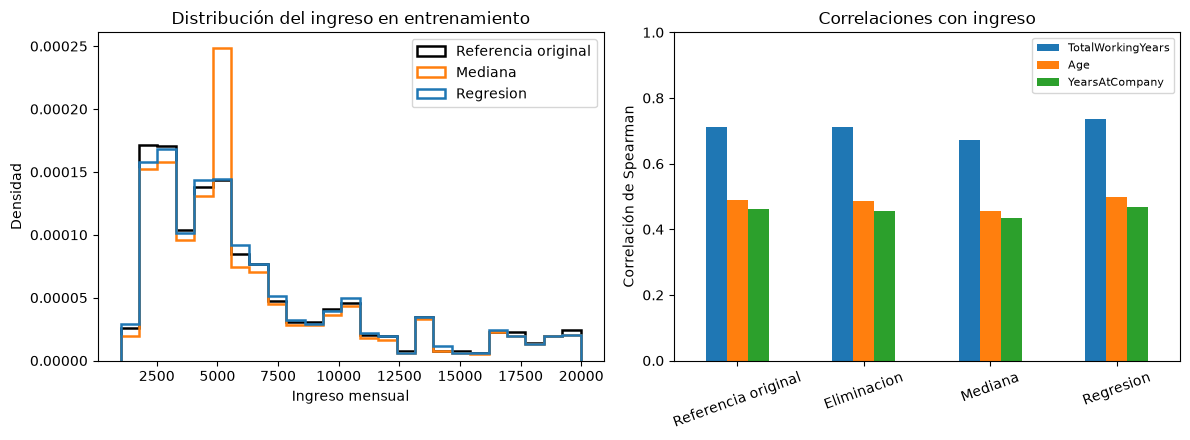

Comparación gráfica guardada.


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

colores = {
    "Referencia original": "black",
    "Mediana": "tab:orange",
    "Regresion": "tab:blue",
}

bins = np.linspace(
    referencia_train["MonthlyIncome"].min(),
    max(
        referencia_train["MonthlyIncome"].max(),
        train_regresion["MonthlyIncome"].max(),
    ),
    26,
)

for nombre, color in colores.items():
    axes[0].hist(
        conjuntos_comparacion[nombre]["MonthlyIncome"],
        bins=bins,
        density=True,
        histtype="step",
        linewidth=1.8,
        color=color,
        label=nombre,
    )

axes[0].set(
    xlabel="Ingreso mensual",
    ylabel="Densidad",
    title="Distribución del ingreso en entrenamiento",
)
axes[0].legend()

comparacion_correlaciones.set_index("Estrategia")[
    PREDICTORES_IMPUTACION
].plot.bar(ax=axes[1])

axes[1].set(
    ylabel="Correlación de Spearman",
    xlabel="",
    title="Correlaciones con ingreso",
    ylim=(0, 1),
)
axes[1].tick_params(axis="x", rotation=20)
axes[1].legend(fontsize=8)

fig.tight_layout()
fig.savefig(
    DIRECTORIO_S3 / "figuras" / "hernan_comparacion_imputacion.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

print("Comparación gráfica guardada.")

## 11. Insumos compartidos para el modelamiento logístico

Se exportaron las versiones de entrenamiento y prueba para eliminación,
mediana y regresión. Se selecciona regresión como estrategia principal,
manteniendo las alternativas para el análisis de sensibilidad.

Los archivos conservan las variables en sus unidades originales.
La codificación y estandarización del modelo logístico se ajustarán
exclusivamente con entrenamiento. EmployeeNumber es un identificador
y Attrition es la respuesta; ninguno debe incorporarse como predictor.

Durante la validación cruzada, la imputación y la estandarización deben
ajustarse nuevamente dentro de cada pliegue de entrenamiento. Utilizar
directamente datos transformados con todo el entrenamiento introduciría
información del pliegue de validación.

In [12]:
# Pesos balanceados calculados solo con entrenamiento.
y_train_base = train["Attrition"].map({"No": 0, "Yes": 1})
frecuencias = y_train_base.value_counts()

pesos_clase = {
    str(clase): float(len(y_train_base) / (2 * frecuencias[clase]))
    for clase in [0, 1]
}

configuracion_s3 = {
    "semilla": SEMILLA,
    "estrategia_principal": "regresion",
    "estrategias_comparacion": [
        "eliminacion",
        "mediana",
        "regresion",
    ],
    "variable_imputada": "MonthlyIncome",
    "predictores_imputacion": PREDICTORES_IMPUTACION,
    "mediana_entrenamiento": float(imputador_mediana.statistics_[0]),
    "predictores_logistica_base": [
        "OverTime",
        "MonthlyIncome",
        "YearsAtCompany",
        "JobSatisfaction",
    ],
    "objetivo": "Attrition",
    "codificacion_objetivo": {"No": 0, "Yes": 1},
    "pesos_balanceados_entrenamiento_principal": pesos_clase,
    "particion": "Formativa2/datos/particion_70_30.csv",
    "datos_MCAR": "Formativa2/datos/IBM_HR_MCAR.csv",
    "referencia_F2": {
        "recall": 4 / 71,
        "AUC": 0.7724210125618576,
        "umbral": 0.5,
    },
    "validacion": (
        "Ajustar imputacion, escalado, seleccion y pesos "
        "dentro del entrenamiento de cada pliegue."
    ),
}

(
    DIRECTORIO_S3 / "resultados" / "configuracion_s3.json"
).write_text(
    json.dumps(configuracion_s3, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

resumen_datos.to_csv(
    DIRECTORIO_S3 / "resultados" / "hernan_particion_recuperada.csv",
    index=False,
)

print("Estrategia principal: regresión.")
print("Pesos balanceados de entrenamiento:", pesos_clase)
print("Configuración compartida guardada.")

Estrategia principal: regresión.
Pesos balanceados de entrenamiento: {'0': 0.5961761297798378, '1': 3.0993975903614457}
Configuración compartida guardada.


# Parte 2. Selección y diagnóstico de modelos


In [13]:
from pathlib import Path
import json
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import sklearn
import statsmodels
import statsmodels.api as sm
from scipy import stats
from sklearn.model_selection import RepeatedStratifiedKFold
from statsmodels.stats.outliers_influence import variance_inflation_factor

RAIZ = next(
    (
        carpeta
        for carpeta in [Path.cwd(), *Path.cwd().parents]
        if (
            carpeta / "datos" / "WA_Fn-UseC_-HR-Employee-Attrition.csv"
        ).is_file()
    ),
    None,
)

if RAIZ is None:
    raise FileNotFoundError("No se encontró la raíz del repositorio.")

DIRECTORIO_F2 = RAIZ / "Formativa2"
DIRECTORIO_S2 = RAIZ / "S2"
DIRECTORIO_S3 = RAIZ / "S3"
RESULTADOS = DIRECTORIO_S3 / "resultados"
FIGURAS = DIRECTORIO_S3 / "figuras"
RESULTADOS.mkdir(parents=True, exist_ok=True)
FIGURAS.mkdir(parents=True, exist_ok=True)

# Funciones del modelamiento (imputación, diseño, ajuste, selección y CV).
sys.path.insert(0, str(DIRECTORIO_S3 / "src"))
from lenin_modelado import (  # noqa: E402
    ImputadorRegresion,
    PreparadorDiseno,
    ajustar_logit,
    codificar_objetivo,
    columnas_de,
    mejor_subconjunto,
    metricas_clasificacion,
    pesos_balanceados,
    preparar_pliegue,
    reajustar_modelo_final,
    stepwise,
    tabla_coeficientes,
    valores_base,
)

config_s3 = json.loads(
    (RESULTADOS / "configuracion_s3.json").read_text(encoding="utf-8")
)

assert config_s3["estrategia_principal"] == "regresion"
assert config_s3["variable_imputada"] == "MonthlyIncome"

SEMILLA = config_s3["semilla"]
UMBRAL = config_s3["referencia_F2"]["umbral"]
PREDICTORES_M1 = config_s3["predictores_logistica_base"]

pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 90)

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__, "| statsmodels:", statsmodels.__version__,
      "| scikit-learn:", sklearn.__version__, "| SciPy:", scipy.__version__)
print("Estrategia principal de imputación:", config_s3["estrategia_principal"])
print("Predictores de imputación:", config_s3["predictores_imputacion"])

Python: 3.14.2
pandas: 3.0.6 | statsmodels: 0.15.0 | scikit-learn: 1.9.1 | SciPy: 1.18.1
Estrategia principal de imputación: regresion
Predictores de imputación: ['TotalWorkingYears', 'Age', 'YearsAtCompany']


## 1. Datos MCAR, partición e imputación principal

Se recuperan los datos MCAR de Formativa 2 (147 ingresos ocultados) y la
partición estratificada 70/30. Se reajusta la imputación por regresión con
los ingresos observados del entrenamiento y se comprueba que reproduce
exactamente `S3/datos/regresion_train.csv` de Hernán.

Esta versión imputada con todo el entrenamiento se usa para **seleccionar
variables y ajustar los modelos finales**. Para la validación cruzada se
vuelve a los datos MCAR con faltantes (sección 7).

In [14]:
df_mcar = pd.read_csv(RAIZ / config_s3["datos_MCAR"]).set_index("EmployeeNumber")
particion = pd.read_csv(RAIZ / config_s3["particion"]).set_index("EmployeeNumber")

ids_train = particion.index[particion["Conjunto"] == "Entrenamiento"]
ids_test = particion.index[particion["Conjunto"] == "Prueba"]

train_mcar = df_mcar.loc[ids_train].copy()
test_mcar = df_mcar.loc[ids_test].copy()

assert len(train_mcar) == 1029 and len(test_mcar) == 441
assert train_mcar["MonthlyIncome"].isna().sum() == 96
assert test_mcar["MonthlyIncome"].isna().sum() == 51
assert df_mcar.drop(columns="MonthlyIncome").notna().all().all()

y_train = codificar_objetivo(train_mcar[config_s3["objetivo"]])

# Imputación principal ajustada solo con entrenamiento observado.
imputador_final = ImputadorRegresion(
    config_s3["variable_imputada"], config_s3["predictores_imputacion"]
).ajustar(train_mcar)
train_imp = imputador_final.transformar(train_mcar)

# Debe coincidir con los datos exportados por Hernán.
regresion_train = pd.read_csv(
    DIRECTORIO_S3 / "datos" / "regresion_train.csv", index_col="EmployeeNumber"
)
np.testing.assert_allclose(
    train_imp.loc[regresion_train.index, "MonthlyIncome"],
    regresion_train["MonthlyIncome"],
)
coef_hernan = pd.read_csv(
    RESULTADOS / "hernan_imputacion_coeficientes.csv", index_col="Termino"
)["Coeficiente"]
np.testing.assert_allclose(
    imputador_final.coeficientes_.loc[coef_hernan.index], coef_hernan
)
assert not train_imp.isna().any().any()

resumen = pd.DataFrame({
    "Registros": [len(train_mcar), len(test_mcar)],
    "Ingresos faltantes (MCAR)": [
        train_mcar["MonthlyIncome"].isna().sum(),
        test_mcar["MonthlyIncome"].isna().sum(),
    ],
    "Salidas": [int(y_train.sum()), "no se usa"],
}, index=["Entrenamiento", "Prueba"])

display(resumen)
print("Imputación por regresión reproducida (coeficientes y valores).")
print("Proporción de salida en entrenamiento:", round(y_train.mean(), 4))

,Registros,Ingresos faltantes (MCAR),Salidas
Entrenamiento,1029,96,166
Prueba,441,51,no se usa


Imputación por regresión reproducida (coeficientes y valores).
Proporción de salida en entrenamiento: 0.1613


## 2. Variables candidatas y su fundamento en S1/S2

Las candidatas se limitan a variables **ya estudiadas en S1 o S2**, para que
la selección no se convierta en una búsqueda sin hipótesis previas entre las
31 variables disponibles.

| Variable | Tipo y codificación | Fundamento previo |
|----------|---------------------|-------------------|
| OverTime | Binaria (0 = No, 1 = Sí) | S1: salida 30,53 % con horas extra vs 10,44 % sin ellas; χ² = 89,04, V = 0,25. F2: OR ≈ 3,6. |
| MonthlyIncome | Cuantitativa, imputada; estandarizada | S1: diferencia de medias (permanece − sale) 2.045,65 [1.508,24; 2.583,05]. S2: IC BCa de medias [1.499,68; 2.547,25] y de medianas [1.438; 2.460,50]; sensible a la cola alta. |
| YearsAtCompany | Cuantitativa; estandarizada | S1: mediana 3 años en quienes salen vs 6. S2: ρ con TotalWorkingYears 0,59 [0,55; 0,63]. |
| JobSatisfaction | Ordinal 1–4, tratada como lineal; estandarizada | S1: salida 22,84 % en el nivel 1, sobre la tasa general de 16,12 %. F2: OR ≈ 0,74 por DE. |
| Age | Cuantitativa; estandarizada | S1: mediana 32 años en quienes salen vs 36. S2: ρ con TotalWorkingYears 0,66 [0,62; 0,69]. |
| TotalWorkingYears | Cuantitativa; estandarizada | S1: mediana 7 vs 10 años. S2: ρ con ingreso 0,71 [0,68; 0,74]: posible redundancia con ingreso, edad y antigüedad. |
| DistanceFromHome | Cuantitativa; estandarizada | S1: única variable con valor mayor en quienes salen (mediana 9 vs 7). S2: ρ con ingreso 0,00 [−0,05; 0,05]: información no redundante con el ingreso. |
| JobLevel | Ordinal 1–5, tratada como lineal; estandarizada | S2 recomendó examinar cargo, nivel laboral y experiencia como posibles factores asociados a la diferencia de ingreso. Riesgo de colinealidad con MonthlyIncome. |
| Department | Nominal; indicadoras de HR y Sales (referencia R&D) | S1: descrita en frecuencias (R&D 65,37 %; HR 4,29 %, solo 63 personas). Fundamento más débil: controla diferencias de composición entre áreas. |

**Excluidas:** EmployeeNumber (identificador), Attrition (respuesta),
las columnas constantes de S1 y las variables no analizadas en S1/S2
(por ejemplo MaritalStatus, StockOptionLevel o JobRole). JobRole, además,
duplica en gran parte la información de Department y JobLevel.

En la selección, Department entra o sale como un bloque de dos columnas.

In [15]:
CANDIDATAS = [
    "OverTime",
    "MonthlyIncome",
    "YearsAtCompany",
    "JobSatisfaction",
    "Age",
    "TotalWorkingYears",
    "DistanceFromHome",
    "JobLevel",
    "Department",
]
assert set(PREDICTORES_M1) <= set(CANDIDATAS)

tabla_candidatas = pd.DataFrame({
    "Variable": CANDIDATAS,
    "Tipo": ["Binaria", "Cuantitativa (imputada)", "Cuantitativa", "Ordinal 1-4",
             "Cuantitativa", "Cuantitativa", "Cuantitativa", "Ordinal 1-5",
             "Nominal 3 niveles"],
    "Codificacion": ["0/1", "z", "z", "z (lineal)", "z", "z", "z", "z (lineal)",
                     "Indicadoras HR y Sales; referencia R&D"],
    "Fuente fundamento": ["S1 chi-cuadrado; F2", "S1 Welch; S2 bootstrap",
                          "S1 bivariado; S2", "S1 tasas por nivel; F2",
                          "S1 bivariado; S2 correlacion", "S1 bivariado; S2 correlacion",
                          "S1 bivariado; S2 correlacion", "S2 recomendacion S3",
                          "S1 frecuencias"],
    "En M1": [v in PREDICTORES_M1 for v in CANDIDATAS],
})
tabla_candidatas.to_csv(RESULTADOS / "lenin_variables_candidatas.csv", index=False)

# Matriz de diseño con todas las candidatas (parámetros aprendidos en entrenamiento).
preparador_candidatas = PreparadorDiseno(CANDIDATAS).ajustar(train_imp)
X_candidatas = preparador_candidatas.transformar(train_imp)

assert X_candidatas.index.equals(y_train.index)
print("Columnas de diseño:", list(X_candidatas.columns))
print("Dimensión:", X_candidatas.shape)
display(tabla_candidatas)

Columnas de diseño: ['const', 'OverTime', 'MonthlyIncome', 'YearsAtCompany', 'JobSatisfaction', 'Age', 'TotalWorkingYears', 'DistanceFromHome', 'JobLevel', 'Dept_Human Resources', 'Dept_Sales']
Dimensión: (1029, 11)


,Variable,Tipo,Codificacion,Fuente fundamento,En M1
0,OverTime,Binaria,0/1,S1 chi-cuadrado; F2,True
1,MonthlyIncome,Cuantitativa (imputada),z,S1 Welch; S2 bootstrap,True
2,YearsAtCompany,Cuantitativa,z,S1 bivariado; S2,True
3,JobSatisfaction,Ordinal 1-4,z (lineal),S1 tasas por nivel; F2,True
4,Age,Cuantitativa,z,S1 bivariado; S2 correlacion,False
5,TotalWorkingYears,Cuantitativa,z,S1 bivariado; S2 correlacion,False
6,DistanceFromHome,Cuantitativa,z,S1 bivariado; S2 correlacion,False
7,JobLevel,Ordinal 1-5,z (lineal),S2 recomendacion S3,False
8,Department,Nominal 3 niveles,Indicadoras HR y Sales; referencia R&D,S1 frecuencias,False


## 3. Multicolinealidad entre candidatas: ingreso y JobLevel

El VIF de un predictor es $\text{VIF}_j = 1/(1-R_j^2)$, donde $R_j^2$ es el
$R^2$ de regresionar ese predictor sobre los demás. Se calcula con intercepto
y no depende de la variable respuesta.

Se compara el conjunto completo de candidatas con dos versiones que excluyen
alternativamente MonthlyIncome o JobLevel, porque en un dataset de RR.HH. el
ingreso se fija en gran parte según el nivel del cargo.

In [16]:
def tabla_vif(X):
    matriz = X.to_numpy(dtype=float)
    return pd.Series(
        [variance_inflation_factor(matriz, i) for i in range(matriz.shape[1])],
        index=X.columns,
    ).drop("const")


vif_candidatas = pd.DataFrame({
    "Todas las candidatas": tabla_vif(X_candidatas),
    "Sin JobLevel": tabla_vif(X_candidatas.drop(columns="JobLevel")),
    "Sin MonthlyIncome": tabla_vif(X_candidatas.drop(columns="MonthlyIncome")),
})
vif_candidatas.index.name = "Columna"
vif_candidatas.to_csv(RESULTADOS / "lenin_vif_candidatas.csv")

rho_ingreso_nivel = stats.spearmanr(
    train_imp["MonthlyIncome"], train_imp["JobLevel"]
).statistic

ingreso_por_nivel = (
    train_imp.groupby("JobLevel")["MonthlyIncome"]
    .agg(Registros="size", Mediana="median", Minimo="min", Maximo="max")
)

display(vif_candidatas.round(2))
print(f"Spearman MonthlyIncome - JobLevel (entrenamiento): {rho_ingreso_nivel:.3f}")
display(ingreso_por_nivel.round(0))

,Todas las candidatas,Sin JobLevel,Sin MonthlyIncome
Columna,,,
Age,1.99,1.99,1.99
Dept_Human Resources,1.02,1.02,1.02
Dept_Sales,1.08,1.04,1.08
DistanceFromHome,1.01,1.00,1.00
JobLevel,7.83,NaN,2.73
JobSatisfaction,1.00,1.00,1.00
MonthlyIncome,7.84,2.73,NaN
OverTime,1.01,1.01,1.01
TotalWorkingYears,4.71,4.62,4.43


Spearman MonthlyIncome - JobLevel (entrenamiento): 0.902


,Registros,Mediana,Minimo,Maximo
JobLevel,,,,
1,362,2694.0,1009.0,10507.0
2,382,5340.0,2042.0,10333.0
3,165,9756.0,5210.0,14195.0
4,78,15890.0,5565.0,17924.0
5,42,19074.0,10822.0,19973.0


Con todas las candidatas, MonthlyIncome y JobLevel tienen VIF de 7,84 y 7,83:
cada uno queda explicado en cerca de un 87 % por los demás predictores
($R_j^2 = 1 - 1/\text{VIF}_j$). La correlación de Spearman entre ambos es 0,90
y la mediana del ingreso sube en cada nivel, de 2.694 en el nivel 1 a 19.074 en
el nivel 5. Al retirar cualquiera de los dos, el VIF del otro baja a 2,73.

TotalWorkingYears se mantiene cerca de 4,5 en las tres versiones, coherente con
sus correlaciones de S2 con ingreso, edad y antigüedad.

Ingreso y JobLevel miden en gran parte lo mismo: la posición del empleado en la
estructura salarial. Si un modelo los incluye juntos, sus coeficientes
individuales pierden precisión y no conviene interpretarlos por separado. Se
revisa el VIF de cada modelo seleccionado (sección 7).

## 4. M1: modelo base sin ponderación

M1 reproduce la especificación de F2 con la nueva imputación por regresión:

$$
\log\frac{p}{1-p} = \beta_0 + \beta_1\,\text{OverTime} + \beta_2\,\text{MonthlyIncome}_z
+ \beta_3\,\text{YearsAtCompany}_z + \beta_4\,\text{JobSatisfaction}_z
$$

donde $p = P(\text{Attrition}=1)$ y el subíndice $z$ indica variable
estandarizada con media y desviación del entrenamiento. Se ajusta por máxima
verosimilitud (`sm.Logit`).

In [17]:
def ajustar_especificacion(variables, pesos=None):
    """Ajusta una especificación sobre la misma matriz de entrenamiento."""
    columnas = ["const", *columnas_de(variables)]
    return ajustar_logit(X_candidatas[columnas], y_train, pesos)


resultado_m1 = ajustar_especificacion(PREDICTORES_M1)

coef_f2 = pd.read_csv(
    DIRECTORIO_F2 / "resultados" / "lenin_logistica_coeficientes.csv",
    index_col="Término",
)

comparacion_f2 = pd.DataFrame({
    "OR F2 (mediana)": coef_f2["Odds ratio"],
    "OR M1 S3 (regresion)": np.exp(resultado_m1.params),
})

print(resultado_m1.summary2().tables[0].iloc[:, :2].to_string(header=False))
display(tabla_coeficientes(resultado_m1).round(4))
display(comparacion_f2.round(3))

0               Model:             Logit
1  Dependent Variable:         Attrition
2                Date:  2026-10-25 16:06
3    No. Observations:              1029
4            Df Model:                 4
5        Df Residuals:              1024
6           Converged:            1.0000
7      No. Iterations:            7.0000


,Coeficiente,Error estandar,z,Valor p,IC95 coef inferior,IC95 coef superior,OR,IC95 OR inferior,IC95 OR superior
Termino,,,,,,,,,
const,-2.3229,0.1345,-17.2691,0.0000,-2.5865,-2.0592,0.0980,0.0753,0.1276
OverTime,1.2944,0.1821,7.1065,0.0000,0.9374,1.6514,3.6489,2.5534,5.2144
MonthlyIncome,-0.4196,0.1254,-3.3450,0.0008,-0.6654,-0.1737,0.6573,0.5141,0.8405
YearsAtCompany,-0.4851,0.1362,-3.5609,0.0004,-0.7521,-0.2181,0.6156,0.4714,0.8041
JobSatisfaction,-0.3070,0.0881,-3.4832,0.0005,-0.4798,-0.1343,0.7356,0.6189,0.8744


,OR F2 (mediana),OR M1 S3 (regresion)
const,0.098,0.098
OverTime,3.611,3.649
MonthlyIncome,0.650,0.657
YearsAtCompany,0.609,0.616
JobSatisfaction,0.736,0.736


Con la imputación por regresión, los OR de M1 son casi idénticos a los de F2
(imputación por mediana): OverTime 3,65 frente a 3,61; ingreso 0,657 frente a
0,650; antigüedad 0,616 frente a 0,609; satisfacción 0,736 en ambos. Como solo
96 de 1.029 ingresos de entrenamiento (9,3 %) están imputados, el método de
imputación cambia poco este modelo. Los cuatro predictores siguen siendo
significativos al 5 %.

## 5. M2: selección stepwise por AIC

$\text{AIC} = -2\,\ell(\hat\beta) + 2k$, donde $\ell$ es la log-verosimilitud
y $k$ el número de parámetros. Penaliza poco la complejidad y prioriza la
capacidad predictiva.

El procedimiento es bidireccional: en cada paso evalúa agregar cualquier
candidata ausente o quitar cualquiera presente, aplica el movimiento que más
reduce el AIC y termina cuando ninguno lo reduce. Se ejecuta desde el modelo
nulo y desde el modelo completo para comprobar que no depende del punto de
partida. Como hay solo 9 bloques, también se verifica contra la búsqueda
exhaustiva de los 512 subconjuntos.

In [18]:
variables_m2, traza_aic = stepwise(X_candidatas, y_train, CANDIDATAS, criterio="aic")
variables_m2_desde_completo, traza_aic_completo = stepwise(
    X_candidatas, y_train, CANDIDATAS, criterio="aic", inicio=CANDIDATAS
)

# Búsqueda exhaustiva: se reutiliza para M3 y para verificar M2.
_, tabla_subconjuntos = mejor_subconjunto(
    X_candidatas, y_train, CANDIDATAS, criterio="bic"
)
mejor_aic_exhaustivo = tabla_subconjuntos.sort_values("AIC").iloc[0]

assert variables_m2 == variables_m2_desde_completo
assert mejor_aic_exhaustivo["Variables"] == ", ".join(variables_m2)

traza_aic.insert(0, "Inicio", "Modelo nulo")
traza_aic_completo.insert(0, "Inicio", "Modelo completo")
pd.concat([traza_aic, traza_aic_completo]).to_csv(
    RESULTADOS / "lenin_stepwise_aic_traza.csv", index=False
)

print("Variables M2:", variables_m2)
display(traza_aic.round(2))

Variables M2: ['OverTime', 'YearsAtCompany', 'JobSatisfaction', 'Age', 'DistanceFromHome', 'JobLevel', 'Department']


,Inicio,Paso,Movimiento,Variable,Criterio,Variables
0,Modelo nulo,0,inicio,-,911.34,(solo intercepto)
1,Modelo nulo,1,agregar,OverTime,868.79,OverTime
2,Modelo nulo,2,agregar,TotalWorkingYears,820.44,"OverTime, TotalWorkingYears"
3,Modelo nulo,3,agregar,JobSatisfaction,809.27,"OverTime, TotalWorkingYears, JobSatisfaction"
4,Modelo nulo,4,agregar,Department,799.95,"OverTime, TotalWorkingYears, JobSatisfaction, Department"
5,Modelo nulo,5,agregar,Age,794.68,"OverTime, TotalWorkingYears, JobSatisfaction, Department, Age"
6,Modelo nulo,6,agregar,YearsAtCompany,788.91,"OverTime, TotalWorkingYears, JobSatisfaction, Department, Age, YearsAtCompany"
7,Modelo nulo,7,agregar,DistanceFromHome,785.08,"OverTime, TotalWorkingYears, JobSatisfaction, Department, Age, YearsAtCompany, Distanc..."
8,Modelo nulo,8,agregar,JobLevel,782.78,"OverTime, TotalWorkingYears, JobSatisfaction, Department, Age, YearsAtCompany, Distanc..."
9,Modelo nulo,9,quitar,TotalWorkingYears,780.79,"OverTime, JobSatisfaction, Department, Age, YearsAtCompany, DistanceFromHome, JobLevel"


Desde el modelo nulo entran, en orden, OverTime (AIC de 911,34 a 868,79),
TotalWorkingYears, JobSatisfaction, Department, Age, YearsAtCompany,
DistanceFromHome y JobLevel. En el último paso **sale TotalWorkingYears**
(782,78 a 780,79): con edad, antigüedad y nivel del cargo en el modelo, la
experiencia total queda redundante. El resultado es el mismo desde el modelo
completo y coincide con la búsqueda exhaustiva.

**M2:** OverTime, YearsAtCompany, JobSatisfaction, Age, DistanceFromHome,
JobLevel y Department (9 parámetros).

MonthlyIncome no entra. Esto no contradice S1 y S2: la diferencia de ingresos
entre quienes salen y quienes permanecen existe, pero en este modelo queda
representada por el nivel del cargo y la trayectoria. Como ingreso y JobLevel
no aparecen juntos, el problema de VIF de la sección 3 no se presenta en M2.

## 6. M3: modelo reducido por BIC

$\text{BIC} = -2\,\ell(\hat\beta) + k\,\ln n$. Con $n = 1.029$, cada parámetro
cuesta $\ln(1.029) \approx 6{,}94$ unidades, frente a 2 en el AIC; por eso BIC
favorece modelos más pequeños.

M3 es el subconjunto con menor BIC entre los 512 posibles (búsqueda
exhaustiva). Se comprueba con un *stepwise* por BIC.

In [19]:
variables_m3, _ = mejor_subconjunto(X_candidatas, y_train, CANDIDATAS, criterio="bic")
variables_m3_stepwise, _ = stepwise(X_candidatas, y_train, CANDIDATAS, criterio="bic")
assert variables_m3 == variables_m3_stepwise

tabla_subconjuntos["Delta BIC"] = (
    tabla_subconjuntos["BIC"] - tabla_subconjuntos["BIC"].min()
)
tabla_subconjuntos.to_csv(RESULTADOS / "lenin_subconjuntos_aic_bic.csv", index=False)

print("Variables M3:", variables_m3)
display(tabla_subconjuntos.head(8).round(2))

Variables M3: ['OverTime', 'YearsAtCompany', 'JobSatisfaction', 'Age', 'Department']


,Variables,Numero variables,Parametros,AIC,BIC,Delta BIC
0,"OverTime, YearsAtCompany, JobSatisfaction, Age, Department",5,7,788.66,823.21,0.00
1,"OverTime, YearsAtCompany, JobSatisfaction, Age",4,5,798.68,823.36,0.15
2,"OverTime, YearsAtCompany, JobSatisfaction, Age, DistanceFromHome",5,6,795.00,824.62,1.41
3,"OverTime, YearsAtCompany, JobSatisfaction, Age, DistanceFromHome, Department",6,8,785.30,824.79,1.58
4,"OverTime, YearsAtCompany, JobSatisfaction, Age, JobLevel, Department",6,8,785.35,824.84,1.63
5,"OverTime, YearsAtCompany, JobSatisfaction, Age, DistanceFromHome, JobLevel, Department",7,9,780.79,825.21,2.00
6,"OverTime, JobSatisfaction, Age, DistanceFromHome, JobLevel, Department",6,8,786.55,826.04,2.83
7,"OverTime, JobSatisfaction, Age, JobLevel, Department",5,7,791.60,826.16,2.95


El mejor subconjunto por BIC es OverTime, YearsAtCompany, JobSatisfaction, Age
y Department (7 parámetros, BIC 823,21). El segundo, sin Department, está a
solo 0,15 unidades, y los seis primeros quedan a menos de 2 unidades. Una
diferencia de BIC menor que 2 se considera evidencia débil, por lo que M3 es el
más parsimonioso de un grupo de modelos casi equivalentes, no un ganador claro.
M2 aparece en sexto lugar, con $\Delta$BIC = 2,00.

## 7. Comparación de los ajustes sin ponderación

Los tres modelos se ajustan sobre las mismas 1.029 observaciones y la misma
matriz de diseño, condición necesaria para comparar AIC y BIC. M3 está anidado
en M2, por lo que además se aplica una prueba de razón de verosimilitudes.
M1 no está anidado en los otros.

También se evalúa qué ocurre con M2 si se usa el ingreso en lugar de JobLevel,
o ambos juntos.

In [20]:
ESPECIFICACIONES = {"M1": PREDICTORES_M1, "M2": variables_m2, "M3": variables_m3}
resultados_sp = {m: ajustar_especificacion(v) for m, v in ESPECIFICACIONES.items()}

assert len({int(r.nobs) for r in resultados_sp.values()}) == 1


def fila_ajuste(nombre, variables, resultado):
    vif_max = tabla_vif(X_candidatas[["const", *columnas_de(variables)]]).max()
    return {
        "Modelo": nombre,
        "Variables": ", ".join(variables),
        "Parametros": int(resultado.df_model + 1),
        "Observaciones": int(resultado.nobs),
        "Log-verosimilitud": resultado.llf,
        "AIC": resultado.aic,
        "BIC": resultado.bic,
        "Pseudo R2 McFadden": resultado.prsquared,
        "VIF maximo": vif_max,
    }


comparacion_ajuste = pd.DataFrame(
    [fila_ajuste(m, ESPECIFICACIONES[m], r) for m, r in resultados_sp.items()]
)

# Variantes de M2 para la discusión ingreso / JobLevel.
m2_con_ingreso = [v if v != "JobLevel" else "MonthlyIncome" for v in variables_m2]
m2_con_ambos = [*variables_m2, "MonthlyIncome"]
variantes = pd.DataFrame([
    fila_ajuste("M2 con ingreso en vez de JobLevel", m2_con_ingreso,
                ajustar_especificacion(m2_con_ingreso)),
    fila_ajuste("M2 + MonthlyIncome", m2_con_ambos,
                ajustar_especificacion(m2_con_ambos)),
])
comparacion_ajuste = pd.concat([comparacion_ajuste, variantes], ignore_index=True)
comparacion_ajuste.to_csv(RESULTADOS / "lenin_comparacion_ajuste_sin_ponderar.csv",
                          index=False)

# Razón de verosimilitudes M3 (reducido) frente a M2.
assert set(variables_m3) <= set(variables_m2)
lr = 2 * (resultados_sp["M2"].llf - resultados_sp["M3"].llf)
gl = int(resultados_sp["M2"].df_model - resultados_sp["M3"].df_model)
p_lr = stats.chi2.sf(lr, gl)

display(comparacion_ajuste.drop(columns="Variables").round(3))
print(f"LR M2 vs M3: estadístico = {lr:.3f}, gl = {gl}, p = {p_lr:.4f}")

,Modelo,Parametros,Observaciones,Log-verosimilitud,AIC,BIC,Pseudo R2 McFadden,VIF maximo
0,M1,5,1029,-402.084,814.168,838.850,0.116,1.332
1,M2,9,1029,-381.393,780.786,825.213,0.161,1.768
2,M3,7,1029,-387.328,788.656,823.210,0.148,1.103
3,M2 con ingreso en vez de JobLevel,9,1029,-382.769,783.538,827.965,0.158,1.694
4,M2 + MonthlyIncome,10,1029,-381.300,782.601,831.964,0.161,7.677


LR M2 vs M3: estadístico = 11.870, gl = 2, p = 0.0026


M2 tiene el menor AIC (780,79) y M3 el menor BIC (823,21), como se espera de sus
penalizaciones. M1 queda último en ambos (AIC 814,17; BIC 838,85): las variables
agregadas mejoran el ajuste más de lo que cuestan. El pseudo $R^2$ de McFadden
es 0,116 en M1, 0,148 en M3 y 0,161 en M2.

La prueba de razón de verosimilitudes rechaza M3 frente a M2 (LR = 11,87,
2 gl, p = 0,0026): DistanceFromHome y JobLevel aportan en conjunto.

Sobre ingreso y JobLevel: reemplazar JobLevel por el ingreso en M2 empeora el
AIC en 2,75 unidades (783,54), y agregar el ingreso a M2 también lo empeora
(782,60) y sube el VIF máximo a 7,68. La evidencia favorece a JobLevel como
resumen de la posición en la empresa, y no usar ambos. En M1, M2 y M3 todos los
VIF son menores que 1,8.

## 8. Versiones ponderadas: efecto del desbalance

Con 16,13 % de salidas, un modelo sin ponderar estima probabilidades bajas y,
con umbral 0,5, casi no clasifica salidas (F2: recall 0,056 en prueba).

Los pesos balanceados se calculan solo con entrenamiento:

$$
w_c = \frac{n}{2\,n_c}, \qquad c \in \{0, 1\}
$$

donde $n_c$ es el número de registros de la clase $c$. Así, cada clase aporta
la mitad del peso total. Se maximiza la log-verosimilitud ponderada
$\sum_i w_i\,[y_i \log p_i + (1-y_i)\log(1-p_i)]$.

Como los pesos no son frecuencias reales, los errores estándar se calculan con
la covarianza *sándwich* HC0 (robusta), no con la clásica. Abajo se comprueba
esa covarianza con un cálculo matricial directo.

**Resultado teórico útil:** si el modelo logístico está bien especificado,
ponderar por clase cambia sobre todo el intercepto, en aproximadamente
$\ln(w_1/w_0)$; las pendientes deberían cambiar poco.

In [21]:
pesos_train = pesos_balanceados(y_train)
pesos_config = {int(k): v for k, v in
                config_s3["pesos_balanceados_entrenamiento_principal"].items()}

assert np.isclose(pesos_train[0], pesos_config[0]) and np.isclose(pesos_train[1], pesos_config[1])
assert round(pesos_train[0], 3) == 0.596 and round(pesos_train[1], 3) == 3.099

resultados_pond = {m: ajustar_especificacion(v, pesos_train)
                   for m, v in ESPECIFICACIONES.items()}

# Verificación manual de la covarianza sándwich en M2 ponderado.
r = resultados_pond["M2"]
X_m2 = X_candidatas[r.model.exog_names].to_numpy(dtype=float)
w = y_train.map(pesos_train).to_numpy()
p_hat = r.fittedvalues.to_numpy()
pan = (X_m2 * (w * p_hat * (1 - p_hat))[:, None]).T @ X_m2
score = X_m2 * (w * (y_train.to_numpy() - p_hat))[:, None]
cov_sandwich = np.linalg.inv(pan) @ (score.T @ score) @ np.linalg.inv(pan)
np.testing.assert_allclose(np.sqrt(np.diag(cov_sandwich)), r.bse, rtol=1e-6)

filas = []
for modelo in ESPECIFICACIONES:
    for ponderacion, resultado in [("Sin ponderar", resultados_sp[modelo]),
                                   ("Ponderado", resultados_pond[modelo])]:
        tabla = tabla_coeficientes(resultado).reset_index()
        tabla.insert(0, "Ponderacion", ponderacion)
        tabla.insert(0, "Modelo", modelo)
        filas.append(tabla)
coeficientes_modelos = pd.concat(filas, ignore_index=True)
coeficientes_modelos.to_csv(RESULTADOS / "lenin_coeficientes_modelos.csv", index=False)

cambio_coeficientes = pd.DataFrame({
    m: resultados_pond[m].params - resultados_sp[m].params for m in ESPECIFICACIONES
})

print("Pesos de entrenamiento:", {k: round(v, 4) for k, v in pesos_train.items()})
print(f"ln(w1/w0) = {np.log(pesos_train[1] / pesos_train[0]):.3f}")
print("Covarianza sándwich verificada manualmente.")
print("\nCambio en coeficientes (ponderado − sin ponderar):")
display(cambio_coeficientes.round(3))

Pesos de entrenamiento: {0: 0.5962, 1: 3.0994}
ln(w1/w0) = 1.648
Covarianza sándwich verificada manualmente.

Cambio en coeficientes (ponderado − sin ponderar):


,M1,M2,M3
Age,NaN,0.075,0.080
Dept_Human Resources,NaN,-0.140,-0.140
Dept_Sales,NaN,0.089,0.087
DistanceFromHome,NaN,-0.041,NaN
JobLevel,NaN,0.018,NaN
JobSatisfaction,-0.011,0.006,-0.002
MonthlyIncome,0.043,NaN,NaN
OverTime,-0.013,-0.051,-0.041
YearsAtCompany,0.134,0.132,0.108
const,1.688,1.695,1.678


Los pesos (0,5962 y 3,0994) coinciden con `configuracion_s3.json`. En los tres
modelos el intercepto sube entre 1,68 y 1,70, muy cerca de
$\ln(w_1/w_0) = 1{,}648$. Las pendientes cambian menos de 0,15 en escala logit;
el mayor cambio es el de YearsAtCompany (+0,13 en M1 y M2), coherente con la
falta de linealidad que se revisa en la sección 11.

En estos ajustes, la ponderación desplaza las puntuaciones hacia arriba
y modifica poco el orden de los empleados. Las puntuaciones ponderadas
se utilizarán para clasificar con umbral 0,5; no deben interpretarse
directamente como probabilidades de salida en la población original.

La versión sin ponderar constituye una referencia para estimar esas
probabilidades, pero tampoco garantiza calibración. Esta propiedad
requiere una evaluación específica en datos de validación.

## 9. Validación cruzada sin fuga de información

Se usa validación cruzada estratificada de 5 pliegues repetida 5 veces
(25 particiones, semilla 42) sobre el entrenamiento. En **cada** pliegue:

1. Se parte de los datos MCAR originales, con los ingresos faltantes.
2. La regresión de imputación se ajusta solo con los ingresos observados del
   pliegue de ajuste y se aplica a ajuste y validación.
3. Medias y desviaciones de estandarización se calculan con el pliegue de
   ajuste.
4. M2 y M3 se **vuelven a seleccionar** con el pliegue de ajuste (stepwise
   AIC y mejor subconjunto BIC, sin ponderar). Se evalúa así el procedimiento
   completo de selección, no solo el resultado obtenido con todo el
   entrenamiento.
5. Los pesos se recalculan con el pliegue de ajuste.
6. Se ajustan las versiones sin ponderar y ponderadas y se evalúan en el
   pliegue de validación con umbral 0,5.

Métricas: AUC (capacidad de ordenar, independiente del umbral), recall
(proporción de salidas detectadas), precisión y F1 (media armónica de recall
y precisión) para la clase salida.

In [22]:
validacion = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEMILLA)

filas_metricas = []
filas_seleccion = []
inicio = time.perf_counter()

for pliegue, (i_ajuste, i_validacion) in enumerate(validacion.split(train_mcar, y_train), 1):
    ajuste_mcar = train_mcar.iloc[i_ajuste]
    validacion_mcar = train_mcar.iloc[i_validacion]
    y_ajuste = y_train.iloc[i_ajuste]
    y_validacion = y_train.iloc[i_validacion]

    X_ajuste, X_validacion, imputador_pliegue, _ = preparar_pliegue(
        ajuste_mcar, validacion_mcar, CANDIDATAS,
        config_s3["variable_imputada"], config_s3["predictores_imputacion"],
    )
    # Controles de fuga: la imputación usa solo ingresos observados del ajuste.
    assert imputador_pliegue.n_ajuste_ == ajuste_mcar["MonthlyIncome"].notna().sum()
    assert X_ajuste.index.isin(validacion_mcar.index).sum() == 0

    pesos_pliegue = pesos_balanceados(y_ajuste)
    especificaciones_pliegue = {
        "M1": PREDICTORES_M1,
        "M2": stepwise(X_ajuste, y_ajuste, CANDIDATAS, criterio="aic")[0],
        "M3": mejor_subconjunto(X_ajuste, y_ajuste, CANDIDATAS, criterio="bic")[0],
    }

    for modelo, variables in especificaciones_pliegue.items():
        columnas = ["const", *columnas_de(variables)]
        filas_seleccion.append({
            "Pliegue": pliegue, "Modelo": modelo,
            "Variables": ", ".join(variables),
            **{v: v in variables for v in CANDIDATAS},
        })
        for ponderacion, pesos in [("Sin ponderar", None), ("Ponderado", pesos_pliegue)]:
            resultado = ajustar_logit(X_ajuste[columnas], y_ajuste, pesos)
            probabilidades = resultado.predict(X_validacion[columnas])
            filas_metricas.append({
                "Pliegue": pliegue, "Modelo": modelo, "Ponderacion": ponderacion,
                "Parametros": len(columnas),
                "Peso clase 0": pesos_pliegue[0], "Peso clase 1": pesos_pliegue[1],
                **metricas_clasificacion(y_validacion, probabilidades, UMBRAL),
            })

metricas_pliegues = pd.DataFrame(filas_metricas)
seleccion_pliegues = pd.DataFrame(filas_seleccion)
metricas_pliegues.to_csv(RESULTADOS / "lenin_validacion_pliegues.csv", index=False)
seleccion_pliegues.to_csv(RESULTADOS / "lenin_seleccion_por_pliegue.csv", index=False)

n_pliegues = metricas_pliegues["Pliegue"].nunique()
METRICAS = ["AUC", "Recall", "Precision", "F1", "Exactitud", "Parametros"]
agrupado = metricas_pliegues.groupby(["Modelo", "Ponderacion"], sort=False)
comparacion_validacion = agrupado[METRICAS].mean().add_suffix(" media")
errores = (agrupado[["AUC", "Recall", "F1"]].std() / np.sqrt(n_pliegues)).add_suffix(" EE")
comparacion_validacion = comparacion_validacion.join(errores).reset_index()
comparacion_validacion.to_csv(RESULTADOS / "lenin_validacion_comparacion.csv", index=False)

estabilidad = (
    seleccion_pliegues.groupby("Modelo")[CANDIDATAS].mean().T
    .rename_axis("Variable").drop(columns="M1")
)
estabilidad.to_csv(RESULTADOS / "lenin_estabilidad_seleccion.csv")

print(f"{n_pliegues} pliegues en {time.perf_counter() - inicio:.1f} s")
print("Rango de pesos recalculados: clase 0",
      metricas_pliegues["Peso clase 0"].agg(["min", "max"]).round(4).tolist(),
      "| clase 1", metricas_pliegues["Peso clase 1"].agg(["min", "max"]).round(4).tolist())
display(comparacion_validacion.round(3))
print("Proporción de pliegues en que se seleccionó cada variable:")
display(estabilidad.round(2))

25 pliegues en 34.1 s
Rango de pesos recalculados: clase 0 [0.5955, 0.5964] | clase 1 [3.094, 3.1174]


,Modelo,Ponderacion,AUC media,Recall media,Precision media,F1 media,Exactitud media,Parametros media,AUC EE,Recall EE,F1 EE
0,M1,Sin ponderar,0.736,0.092,0.704,0.158,0.846,5.0,0.010,0.008,0.013
1,M1,Ponderado,0.732,0.664,0.295,0.408,0.689,5.0,0.010,0.016,0.009
2,M2,Sin ponderar,0.752,0.167,0.673,0.263,0.852,9.0,0.012,0.012,0.017
3,M2,Ponderado,0.747,0.674,0.300,0.415,0.693,9.0,0.011,0.018,0.011
4,M3,Sin ponderar,0.729,0.112,0.619,0.186,0.844,5.6,0.010,0.008,0.012
5,M3,Ponderado,0.727,0.652,0.290,0.401,0.684,5.6,0.010,0.017,0.011


Proporción de pliegues en que se seleccionó cada variable:


Modelo,M2,M3
Variable,,
OverTime,1.00,1.00
MonthlyIncome,0.04,0.00
YearsAtCompany,1.00,0.68
JobSatisfaction,1.00,0.96
Age,0.96,0.76
TotalWorkingYears,0.08,0.24
DistanceFromHome,1.00,0.16
JobLevel,0.92,0.16
Department,1.00,0.32


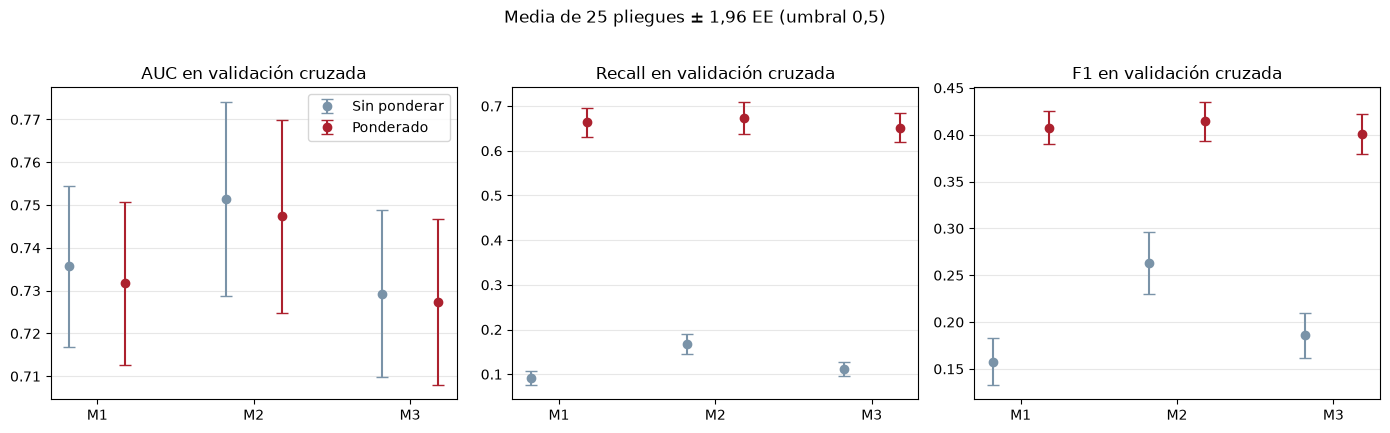

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=False)
colores = {"Sin ponderar": "#7A93A8", "Ponderado": "#AC212E"}
posiciones = np.arange(3)

for eje, metrica in zip(axes, ["AUC", "Recall", "F1"]):
    for desplazamiento, (ponderacion, color) in zip([-0.18, 0.18], colores.items()):
        datos = comparacion_validacion[comparacion_validacion["Ponderacion"] == ponderacion]
        eje.errorbar(
            posiciones + desplazamiento, datos[f"{metrica} media"],
            yerr=datos[f"{metrica} EE"] * 1.96, fmt="o", color=color,
            capsize=4, label=ponderacion,
        )
    eje.set_xticks(posiciones, ["M1", "M2", "M3"])
    eje.set_title(f"{metrica} en validación cruzada")
    eje.grid(axis="y", alpha=0.3)
axes[0].legend(loc="upper right")
fig.suptitle("Media de 25 pliegues ± 1,96 EE (umbral 0,5)", y=1.02)
fig.tight_layout()
fig.savefig(FIGURAS / "lenin_validacion_comparacion.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

**Efecto de la ponderación.** Es la decisión con más impacto: con umbral 0,5,
el recall sube de 0,09–0,17 a 0,65–0,67 y el F1 de 0,16–0,26 a 0,40–0,42. El
costo es la precisión (cerca de 0,30: de cada 10 empleados marcados, 3 salen) y
la exactitud (de 0,85 a 0,69), que con clases desbalanceadas no es una buena
guía. El AUC casi no cambia (diferencias ≤ 0,005), lo que confirma la sección 8:
ponderar mueve el intercepto, no el orden.

**Especificaciones.** M2 tiene el mayor AUC (0,747 ponderado), frente a 0,732
de M1 y 0,727 de M3. Los F1 ponderados son parecidos (0,401 a 0,415).

**Estabilidad de la selección.** El stepwise por AIC elige casi siempre lo mismo:
OverTime, YearsAtCompany, JobSatisfaction, DistanceFromHome y Department en los
25 pliegues, Age en el 96 % y JobLevel en el 92 %; el ingreso, solo en el 4 %.
El BIC es inestable (YearsAtCompany 68 %, Age 76 %, Department 32 %), coherente
con los modelos casi empatados de la sección 6.

Los pesos recalculados por pliegue van de 0,5955 a 0,5964 (permanencia) y de
3,094 a 3,117 (salida).

## 10. Propuesta preliminar según validación interna

La regla se fija antes de mirar la prueba y usa solo la validación interna:

1. **Detección mínima:** descartar versiones con recall medio < 0,50 en
   validación. Un modelo que no detecta al menos la mitad de las salidas no
   sirve para el objetivo de anticipar renuncias.
2. **Regla de un error estándar:** entre las restantes, conservar las que
   tengan AUC **y** F1 medios a no más de 1 EE del mejor valor.
3. **Complejidad:** entre las conservadas, elegir la de menos parámetros;
   si empatan, la de mayor AUC.

El EE de 25 pliegues repetidos subestima la incertidumbre real, porque los
pliegues comparten observaciones; la regla se usa como criterio orientativo.

In [24]:
candidatos = comparacion_validacion[comparacion_validacion["Recall media"] >= 0.5].copy()

mejor_auc = candidatos.loc[candidatos["AUC media"].idxmax()]
mejor_f1 = candidatos.loc[candidatos["F1 media"].idxmax()]
candidatos["Dentro 1 EE AUC"] = candidatos["AUC media"] >= mejor_auc["AUC media"] - mejor_auc["AUC EE"]
candidatos["Dentro 1 EE F1"] = candidatos["F1 media"] >= mejor_f1["F1 media"] - mejor_f1["F1 EE"]

conservados = candidatos[candidatos["Dentro 1 EE AUC"] & candidatos["Dentro 1 EE F1"]]
elegido = conservados.sort_values(["Parametros media", "AUC media"],
                                  ascending=[True, False]).iloc[0]

MODELO_PRELIMINAR = elegido["Modelo"]
PONDERACION_FINAL = "balanceada" if elegido["Ponderacion"] == "Ponderado" else "ninguna"
VARIABLES_PRELIMINARES = ESPECIFICACIONES[MODELO_PRELIMINAR]

# Diferencias pareadas por pliegue frente al modelo elegido (versiones ponderadas).
pareadas = metricas_pliegues[metricas_pliegues["Ponderacion"] == elegido["Ponderacion"]].pivot(
    index="Pliegue", columns="Modelo", values=["AUC", "F1", "Recall"]
)
diferencias = []
for metrica in ["AUC", "F1", "Recall"]:
    for otro in [m for m in ESPECIFICACIONES if m != MODELO_PRELIMINAR]:
        d = pareadas[metrica][MODELO_PRELIMINAR] - pareadas[metrica][otro]
        diferencias.append({
            "Metrica": metrica, "Comparacion": f"{MODELO_PRELIMINAR} - {otro}",
            "Diferencia media": d.mean(), "EE": d.std() / np.sqrt(len(d)),
            "Pliegues a favor": (d > 0).mean(),
        })
diferencias = pd.DataFrame(diferencias)
diferencias.to_csv(RESULTADOS / "lenin_validacion_diferencias_pareadas.csv", index=False)

display(candidatos[["Modelo", "Ponderacion", "AUC media", "F1 media", "Recall media",
                    "Parametros media", "Dentro 1 EE AUC", "Dentro 1 EE F1"]].round(3))
display(diferencias.round(4))
print(f"Propuesta preliminar: {MODELO_PRELIMINAR} | ponderación: {PONDERACION_FINAL}")
print("Variables:", VARIABLES_PRELIMINARES)

,Modelo,Ponderacion,AUC media,F1 media,Recall media,Parametros media,Dentro 1 EE AUC,Dentro 1 EE F1
1,M1,Ponderado,0.732,0.408,0.664,5.0,False,True
3,M2,Ponderado,0.747,0.415,0.674,9.0,True,True
5,M3,Ponderado,0.727,0.401,0.652,5.6,False,False


,Metrica,Comparacion,Diferencia media,EE,Pliegues a favor
0,AUC,M2 - M1,0.0156,0.0056,0.68
1,AUC,M2 - M3,0.0200,0.0032,0.80
2,F1,M2 - M1,0.0070,0.0082,0.64
3,F1,M2 - M3,0.0136,0.0071,0.68
4,Recall,M2 - M1,0.0106,0.0145,0.44
5,Recall,M2 - M3,0.0225,0.0117,0.52


Propuesta preliminar: M2 | ponderación: balanceada
Variables: ['OverTime', 'YearsAtCompany', 'JobSatisfaction', 'Age', 'DistanceFromHome', 'JobLevel', 'Department']


Ninguna versión sin ponderar pasa el filtro de recall. Entre las ponderadas,
M2 tiene el mejor AUC (0,747) y el mejor F1 (0,415). M1 queda dentro de 1 EE en
F1, pero no en AUC (0,732 < 0,736); M3 queda fuera en ambas. La regla deja a
**M2 ponderado** como propuesta preliminar, aunque tiene 9 parámetros frente a
5 de M1.

Las diferencias pareadas respaldan la ventaja en AUC (+0,016 frente a M1, mejor
en el 68 % de los pliegues; +0,020 frente a M3, 80 %), no en recall
(M2 − M1 = +0,011 con EE 0,015).

Sobre la complejidad: hay 166 salidas en entrenamiento y 8 pendientes, unas 21
salidas por parámetro, sobre la referencia habitual de 10. Antes de cerrar la
propuesta se revisa la forma funcional.

## 11. Forma funcional del modelo preliminar

Antes de interpretar coeficientes se revisa el supuesto de **linealidad en el
logit**: cada variable numérica debe relacionarse linealmente con
$\log[p/(1-p)]$, no con la probabilidad.

- **Box-Tidwell:** se agrega el término $x\ln x$ (unidades originales; si la
  variable tiene ceros se desplaza a mínimo 1). Si su coeficiente es
  significativo, hay curvatura no capturada.
- **Ordinales:** para JobSatisfaction y JobLevel se compara la codificación
  lineal con indicadoras por nivel mediante razón de verosimilitudes.
- **Gráfico:** logit empírico por deciles, $\log\frac{s+0{,}5}{n-s+0{,}5}$,
  donde $s$ son las salidas del grupo y $n$ su tamaño.

Estos diagnósticos usan el ajuste sin ponderar (máxima verosimilitud) y solo
el entrenamiento.

,Variable,Prueba,Estadistico,gl,Valor p
0,YearsAtCompany,Box-Tidwell (x ln x),4.8687,1,0.0000
1,JobSatisfaction,LR lineal vs categorica,0.8966,2,0.6387
2,Age,Box-Tidwell (x ln x),3.1480,1,0.0016
3,DistanceFromHome,Box-Tidwell (x ln x),0.0837,1,0.9333
4,JobLevel,LR lineal vs categorica,26.1696,3,0.0000


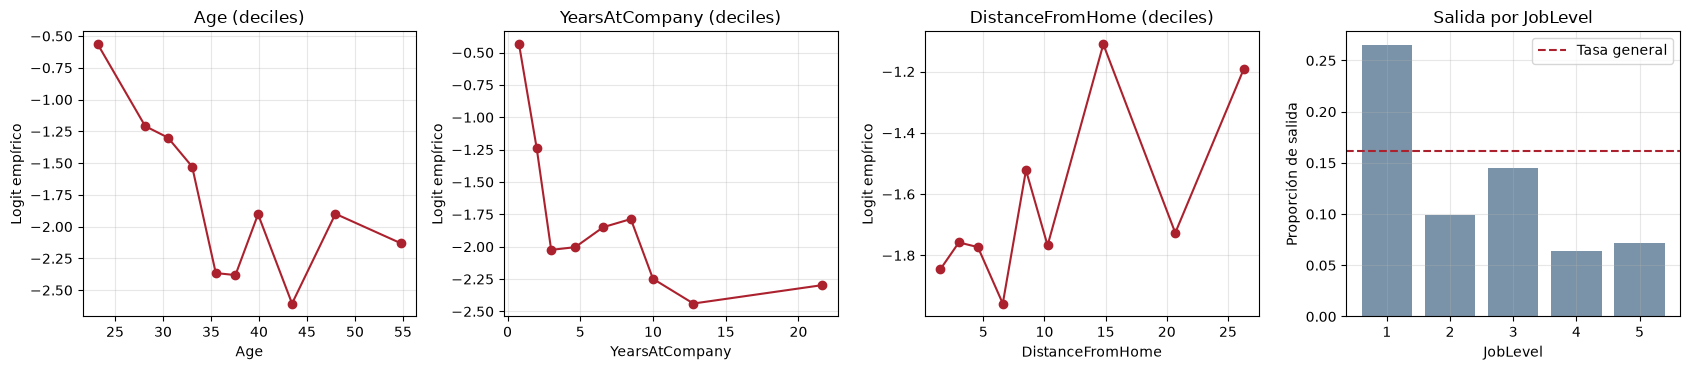

,Proporcion salida,Registros
JobLevel,,
1,0.265,362
2,0.099,382
3,0.145,165
4,0.064,78
5,0.071,42


In [25]:
CONTINUAS = ["Age", "YearsAtCompany", "DistanceFromHome", "MonthlyIncome", "TotalWorkingYears"]
ORDINALES = ["JobSatisfaction", "JobLevel"]


def base_original(nombre):
    """Variable original que da origen a una columna (log_Age -> Age)."""
    for prefijo in ("log1p_", "log_"):
        nombre = nombre.removeprefix(prefijo)
    return nombre


def pruebas_linealidad(variables, X, datos, y):
    """Box-Tidwell para continuas y LR lineal vs categórica para ordinales."""
    resultado_base = ajustar_logit(X, y)
    filas = []
    for variable in variables:
        if base_original(variable) in CONTINUAS:
            x = valores_base(datos, variable)
            x = x - x.min() + 1 if x.min() <= 0 else x
            termino = x * np.log(x)
            X_bt = X.copy()
            X_bt["bt"] = (termino - termino.mean()) / termino.std()
            r_bt = ajustar_logit(X_bt, y)
            filas.append({"Variable": variable, "Prueba": "Box-Tidwell (x ln x)",
                          "Estadistico": r_bt.tvalues["bt"], "gl": 1,
                          "Valor p": r_bt.pvalues["bt"]})
        elif variable in ORDINALES:
            indicadoras = pd.get_dummies(datos[variable], prefix=variable,
                                         drop_first=True, dtype=float)
            r_cat = ajustar_logit(pd.concat([X.drop(columns=variable), indicadoras], axis=1), y)
            estadistico = 2 * (r_cat.llf - resultado_base.llf)
            gl_ord = indicadoras.shape[1] - 1
            filas.append({"Variable": variable, "Prueba": "LR lineal vs categorica",
                          "Estadistico": estadistico, "gl": gl_ord,
                          "Valor p": stats.chi2.sf(estadistico, gl_ord)})
    return pd.DataFrame(filas)


X_preliminar = X_candidatas[["const", *columnas_de(VARIABLES_PRELIMINARES)]]
linealidad_m2 = pruebas_linealidad(VARIABLES_PRELIMINARES, X_preliminar, train_imp, y_train)
linealidad_m2.to_csv(RESULTADOS / "lenin_linealidad_preliminar.csv", index=False)
display(linealidad_m2.round(4))

fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for eje, variable in zip(axes, ["Age", "YearsAtCompany", "DistanceFromHome"]):
    grupos = pd.qcut(train_imp[variable], q=10, duplicates="drop")
    tabla = pd.DataFrame({"x": train_imp[variable], "y": y_train}).groupby(
        grupos, observed=True).agg(x=("x", "mean"), s=("y", "sum"), n=("y", "size"))
    eje.plot(tabla["x"], np.log((tabla["s"] + 0.5) / (tabla["n"] - tabla["s"] + 0.5)),
             "o-", color="#AC212E")
    eje.set(xlabel=variable, ylabel="Logit empírico", title=f"{variable} (deciles)")
tasas_nivel = y_train.groupby(train_imp["JobLevel"]).mean()
axes[3].bar(tasas_nivel.index.astype(str), tasas_nivel, color="#7A93A8")
axes[3].axhline(y_train.mean(), color="#AC212E", linestyle="--", label="Tasa general")
axes[3].set(xlabel="JobLevel", ylabel="Proporción de salida", title="Salida por JobLevel")
axes[3].legend()
for eje in axes:
    eje.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURAS / "lenin_linealidad_preliminar.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)
display(tasas_nivel.rename("Proporcion salida").to_frame().join(
    train_imp["JobLevel"].value_counts().rename("Registros")).round(3))

Box-Tidwell rechaza la linealidad para **YearsAtCompany** (p < 0,001) y
**Age** (p = 0,0016). DistanceFromHome no muestra curvatura (p = 0,93).

JobSatisfaction puede mantenerse como numérica (LR = 0,90, 2 gl, p = 0,64), lo
que responde la duda que quedó abierta en F2. **JobLevel** lineal se rechaza
(LR = 26,17, 3 gl, p < 0,001).

Los gráficos muestran la forma del problema. El logit empírico de la antigüedad
cae con fuerza en los primeros 2 o 3 años y luego se aplana; el de la edad baja
hasta cerca de los 35 años y después oscila sin tendencia clara. En JobLevel la
salida no es monótona: 26,5 % en el nivel 1, 9,9 % en el 2, 14,5 % en el 3 y
6–7 % en los niveles 4 y 5. Una pendiente única subestima la salida en el nivel
de entrada.

En términos de RR.HH., la salida se concentra en el primer período en la empresa
y en los cargos de entrada, un patrón típico de rotación temprana.

## 12. Corrección de la forma funcional: M2c

Se conservan las **mismas siete variables** de M2 y se cambia solo su forma:

| Variable en M2 | Forma en M2c | Justificación |
|----------------|--------------|---------------|
| YearsAtCompany | `log1p_YearsAtCompany` = ln(1 + años) | La salida cae fuerte en los primeros años y luego se estabiliza; S1 ya describió asimetría positiva y colas pesadas (exceso de curtosis 3,94). |
| Age | `log_Age` = ln(edad) | Mayor salida bajo los 33 años y un nivel casi constante después. |
| JobLevel | `ind_JobLevel_1` = 1 si nivel 1 | La salida no es monótona entre niveles; la diferencia principal está entre el nivel de entrada y el resto. |

Primero se comparan variantes por AIC/BIC sobre las mismas 1.029 observaciones.
Luego se comparan las especificaciones fijas M2 y M2c con los mismos
25 pliegues, ajustando imputación, estandarización y pesos únicamente
con la porción de ajuste de cada pliegue.

Sin embargo, las variables y transformaciones se eligieron previamente
utilizando todo el entrenamiento. Por ello, esta comparación no valida
de forma independiente el proceso completo de selección y puede ofrecer
resultados optimistas. Se interpreta como una comparación exploratoria.

El conjunto de prueba no participa en estas decisiones de S3, aunque
ya fue examinado durante F2; su evaluación también tendrá un alcance
exploratorio.

In [26]:
VARIABLES_M2C = [
    {"YearsAtCompany": "log1p_YearsAtCompany", "Age": "log_Age",
     "JobLevel": "ind_JobLevel_1"}.get(v, v)
    for v in VARIABLES_PRELIMINARES
]

variantes_forma = {
    "M2 (lineal)": VARIABLES_PRELIMINARES,
    "M2 + ln(1+YearsAtCompany)": [v.replace("YearsAtCompany", "log1p_YearsAtCompany")
                                  for v in VARIABLES_PRELIMINARES],
    "M2 + ln(1+YearsAtCompany) + ln(Age)": [
        {"YearsAtCompany": "log1p_YearsAtCompany", "Age": "log_Age"}.get(v, v)
        for v in VARIABLES_PRELIMINARES],
    "M2c (+ indicador JobLevel 1)": VARIABLES_M2C,
    "M2c con JobLevel categorico": [
        x for v in VARIABLES_M2C
        for x in ([f"ind_JobLevel_{k}" for k in (2, 3, 4, 5)] if v == "ind_JobLevel_1" else [v])
    ],
}

filas_forma = []
ajustes_forma = {}
for nombre, variables in variantes_forma.items():
    X_var = PreparadorDiseno(variables).ajustar(train_imp).transformar(train_imp)
    r_var = ajustar_logit(X_var, y_train)
    ajustes_forma[nombre] = r_var
    filas_forma.append({"Variante": nombre, "Parametros": int(r_var.df_model + 1),
                        "Observaciones": int(r_var.nobs), "Log-verosimilitud": r_var.llf,
                        "AIC": r_var.aic, "BIC": r_var.bic})
comparacion_forma = pd.DataFrame(filas_forma)
assert comparacion_forma["Observaciones"].nunique() == 1
comparacion_forma.to_csv(RESULTADOS / "lenin_comparacion_forma_funcional.csv", index=False)

lr_cat = 2 * (ajustes_forma["M2c con JobLevel categorico"].llf
              - ajustes_forma["M2c (+ indicador JobLevel 1)"].llf)
p_lr_cat = stats.chi2.sf(lr_cat, 3)

display(comparacion_forma.round(2))
print(f"LR JobLevel categórico (4 indicadoras) vs indicador de nivel 1: "
      f"estadístico = {lr_cat:.3f}, gl = 3, p = {p_lr_cat:.4f}")

,Variante,Parametros,Observaciones,Log-verosimilitud,AIC,BIC
0,M2 (lineal),9,1029,-381.39,780.79,825.21
1,M2 + ln(1+YearsAtCompany),9,1029,-374.07,766.15,810.57
2,M2 + ln(1+YearsAtCompany) + ln(Age),9,1029,-372.72,763.45,807.88
3,M2c (+ indicador JobLevel 1),9,1029,-365.04,748.07,792.50
4,M2c con JobLevel categorico,12,1029,-362.60,749.19,808.43


LR JobLevel categórico (4 indicadoras) vs indicador de nivel 1: estadístico = 4.876, gl = 3, p = 0.1811


In [27]:
def validar_fijas(especificaciones):
    """CV con especificación fija: imputación, escalado y pesos en cada pliegue."""
    filas = []
    for pliegue, (i_aj, i_val) in enumerate(validacion.split(train_mcar, y_train), 1):
        y_aj, y_val = y_train.iloc[i_aj], y_train.iloc[i_val]
        pesos_pl = pesos_balanceados(y_aj)
        for modelo, variables in especificaciones.items():
            X_aj, X_val, _, _ = preparar_pliegue(
                train_mcar.iloc[i_aj], train_mcar.iloc[i_val], variables,
                config_s3["variable_imputada"], config_s3["predictores_imputacion"])
            for ponderacion, pesos in [("Sin ponderar", None), ("Ponderado", pesos_pl)]:
                r_pl = ajustar_logit(X_aj, y_aj, pesos)
                filas.append({"Pliegue": pliegue, "Modelo": modelo, "Ponderacion": ponderacion,
                              "Parametros": X_aj.shape[1],
                              **metricas_clasificacion(y_val, r_pl.predict(X_val), UMBRAL)})
    return pd.DataFrame(filas)


metricas_fijas = validar_fijas({"M2": VARIABLES_PRELIMINARES, "M2c": VARIABLES_M2C})
metricas_fijas.to_csv(RESULTADOS / "lenin_validacion_m2_vs_m2c_pliegues.csv", index=False)

agr = metricas_fijas.groupby(["Modelo", "Ponderacion"], sort=False)
comparacion_fijas = agr[["AUC", "Recall", "Precision", "F1", "Parametros"]].mean().add_suffix(" media").join(
    (agr[["AUC", "Recall", "F1"]].std() / np.sqrt(n_pliegues)).add_suffix(" EE")).reset_index()
comparacion_fijas.to_csv(RESULTADOS / "lenin_validacion_m2_vs_m2c.csv", index=False)

par = metricas_fijas[metricas_fijas["Ponderacion"] == "Ponderado"].pivot(
    index="Pliegue", columns="Modelo", values=["AUC", "Recall", "F1"])
dif_m2c = pd.DataFrame([{
    "Metrica": m, "Diferencia media M2c - M2": (par[m]["M2c"] - par[m]["M2"]).mean(),
    "EE": (par[m]["M2c"] - par[m]["M2"]).std() / np.sqrt(n_pliegues),
    "Pliegues a favor de M2c": ((par[m]["M2c"] - par[m]["M2"]) > 0).mean(),
} for m in ["AUC", "Recall", "F1"]])

display(comparacion_fijas.round(3))
display(dif_m2c.round(4))

# Regla: adoptar M2c si, con igual número de parámetros, no empeora AUC ni F1
# ponderados en validación y reduce el AIC.
fila = lambda m: comparacion_fijas.query("Modelo == @m and Ponderacion == 'Ponderado'").iloc[0]
adoptar_m2c = (
    fila("M2c")["Parametros media"] == fila("M2")["Parametros media"]
    and fila("M2c")["AUC media"] >= fila("M2")["AUC media"]
    and fila("M2c")["F1 media"] >= fila("M2")["F1 media"]
    and ajustes_forma["M2c (+ indicador JobLevel 1)"].aic < ajustes_forma["M2 (lineal)"].aic
)

MODELO_FINAL = "M2c" if adoptar_m2c else MODELO_PRELIMINAR
VARIABLES_FINALES = VARIABLES_M2C if adoptar_m2c else VARIABLES_PRELIMINARES
ESPECIFICACIONES["M2c"] = VARIABLES_M2C
print(f"Modelo final: {MODELO_FINAL} | ponderación: {PONDERACION_FINAL}")
print("Variables:", VARIABLES_FINALES)

,Modelo,Ponderacion,AUC media,Recall media,Precision media,F1 media,Parametros media,AUC EE,Recall EE,F1 EE
0,M2,Sin ponderar,0.755,0.170,0.681,0.267,9.0,0.011,0.012,0.017
1,M2,Ponderado,0.751,0.673,0.299,0.414,9.0,0.011,0.019,0.011
2,M2c,Sin ponderar,0.779,0.221,0.679,0.331,9.0,0.010,0.012,0.017
3,M2c,Ponderado,0.777,0.707,0.329,0.449,9.0,0.010,0.017,0.010


,Metrica,Diferencia media M2c - M2,EE,Pliegues a favor de M2c
0,AUC,0.0263,0.0037,0.92
1,Recall,0.0338,0.0091,0.72
2,F1,0.0348,0.0049,0.92


Modelo final: M2c | ponderación: balanceada
Variables: ['OverTime', 'log1p_YearsAtCompany', 'JobSatisfaction', 'log_Age', 'DistanceFromHome', 'ind_JobLevel_1', 'Department']


Con los mismos 9 parámetros, el AIC baja 32,7 unidades (780,79 a 748,07): 14,6
por ln(1 + YearsAtCompany), 2,7 por ln(Age) y 15,4 por el indicador de nivel 1.
El BIC baja de 825,21 a 792,50. Usar JobLevel completo como categórico
(4 indicadoras) no mejora frente al indicador (LR = 4,88, 3 gl, p = 0,18) y su
BIC es peor (808,43): basta distinguir el nivel 1 del resto.

En validación cruzada, con los mismos pliegues, M2c ponderado obtiene AUC 0,777
frente a 0,751, F1 0,449 frente a 0,414 y recall 0,707 frente a 0,673. Las
diferencias pareadas son +0,026 en AUC (EE 0,004) y +0,035 en F1 (EE 0,005),
favorables a M2c en el 92 % de los pliegues. La regla adopta **M2c ponderado**.

El AUC de M2 con especificación fija es 0,751, frente a 0,747 cuando
la selección se repite dentro de cada pliegue. Esta diferencia es
descriptiva y no permite cuantificar el optimismo de M2c ni corregir
su desempeño estimado. Para evaluar el proceso completo sería necesario
repetir también la selección de transformaciones dentro de la validación.

## 13. Modelo final: coeficientes, odds ratios e intervalos

Se ajusta la especificación final con todo el entrenamiento. Se presentan:

- **Ponderado (modelo final):** coeficientes de la versión que se usará para
  clasificar; errores estándar sándwich HC0.
- **Sin ponderar:** misma especificación por máxima verosimilitud; su
  intercepto conserva la prevalencia observada y sirve de referencia para las
  pendientes.

El OR es $e^{\beta}$. Las variables estandarizadas comparan un aumento de una
desviación estándar (DE), manteniendo constantes las demás. Para las variables
en logaritmo, +1 DE equivale a **multiplicar** la variable (o 1 + años) por
$e^{\text{DE}}$; ese factor se informa en la tabla.

In [28]:
preparador_final = PreparadorDiseno(VARIABLES_FINALES).ajustar(train_imp)
X_final = preparador_final.transformar(train_imp)
assert X_final.index.equals(y_train.index) and not X_final.isna().any().any()

pesos_final = pesos_train if PONDERACION_FINAL == "balanceada" else None
resultado_final = ajustar_logit(X_final, y_train, pesos_final)
resultado_final_sp = ajustar_logit(X_final, y_train)

coef_final = tabla_coeficientes(resultado_final)
coef_final_sp = tabla_coeficientes(resultado_final_sp)
coef_final.to_csv(RESULTADOS / "lenin_coeficientes_modelo_final.csv")
coef_final_sp.to_csv(RESULTADOS / "lenin_coeficientes_modelo_final_sin_ponderar.csv")

tabla_final = coef_final[["Coeficiente", "Error estandar", "Valor p", "OR",
                          "IC95 OR inferior", "IC95 OR superior"]].join(
    coef_final_sp[["Coeficiente", "Valor p", "OR", "IC95 OR inferior", "IC95 OR superior"]],
    rsuffix=" sin ponderar")

escalado_final = preparador_final.parametros().set_index("Variable")
unidades = {"YearsAtCompany": "años", "Age": "años", "DistanceFromHome": "unidades",
            "JobSatisfaction": "niveles", "JobLevel": "niveles",
            "MonthlyIncome": "unidades monetarias", "TotalWorkingYears": "años"}
filas_int = []
for termino in coef_final.index.drop("const"):
    if termino in escalado_final.index:
        de = escalado_final.loc[termino, "Desviacion ajuste"]
        if termino.startswith("log1p_"):
            texto = f"+1 DE: (1 + años) × {np.exp(de):.2f}"
        elif termino.startswith("log_"):
            texto = f"+1 DE: edad × {np.exp(de):.2f}"
        else:
            texto = f"+1 DE (≈ {de:.1f} {unidades[termino]})"
    elif termino == "OverTime":
        texto = "Sí frente a No"
    elif termino.startswith("ind_"):
        texto = "Nivel 1 frente a niveles 2-5"
    else:
        texto = f"{termino.removeprefix('Dept_')} frente a R&D"
    filas_int.append({
        "Termino": termino, "Comparacion": texto,
        "OR ponderado": coef_final.loc[termino, "OR"],
        "IC95 inferior": coef_final.loc[termino, "IC95 OR inferior"],
        "IC95 superior": coef_final.loc[termino, "IC95 OR superior"],
        "OR sin ponderar": coef_final_sp.loc[termino, "OR"],
        "Cambio en odds (%)": (coef_final.loc[termino, "OR"] - 1) * 100,
        # Para variables en log: OR al duplicar la variable (o 1 + años).
        "OR al duplicar": (np.exp(coef_final.loc[termino, "Coeficiente"]
                                  / escalado_final.loc[termino, "Desviacion ajuste"] * np.log(2))
                           if termino.startswith("log") else np.nan),
    })
interpretacion = pd.DataFrame(filas_int).set_index("Termino")
interpretacion.to_csv(RESULTADOS / "lenin_interpretacion_or_modelo_final.csv")

display(tabla_final.round(4))
display(interpretacion.round(3))
print(f"Intercepto: ponderado − sin ponderar = "
      f"{resultado_final.params['const'] - resultado_final_sp.params['const']:.3f} "
      f"(ln(w1/w0) = {np.log(pesos_train[1] / pesos_train[0]):.3f})")

,Coeficiente,Error estandar,Valor p,OR,IC95 OR inferior,IC95 OR superior,Coeficiente sin ponderar,Valor p sin ponderar,OR sin ponderar,IC95 OR inferior sin ponderar,IC95 OR superior sin ponderar
Termino,,,,,,,,,,,
const,-1.6034,0.2463,0.0000,0.2012,0.1242,0.3261,-3.3147,0.0000,0.0363,0.0230,0.0574
OverTime,1.3598,0.2036,0.0000,3.8954,2.6136,5.8058,1.4810,0.0000,4.3972,2.9877,6.4715
log1p_YearsAtCompany,-0.3196,0.1095,0.0035,0.7265,0.5861,0.9004,-0.3977,0.0002,0.6719,0.5464,0.8262
JobSatisfaction,-0.3029,0.0958,0.0016,0.7386,0.6122,0.8912,-0.3185,0.0006,0.7272,0.6058,0.8730
log_Age,-0.2709,0.1126,0.0161,0.7627,0.6116,0.9510,-0.3416,0.0012,0.7106,0.5782,0.8735
DistanceFromHome,0.2411,0.0965,0.0125,1.2726,1.0533,1.5376,0.2656,0.0039,1.3042,1.0888,1.5624
ind_JobLevel_1,1.0972,0.2590,0.0000,2.9959,1.8033,4.9774,1.0971,0.0000,2.9954,1.8457,4.8613
Dept_Human Resources,0.3381,0.3799,0.3735,1.4023,0.6660,2.9523,0.5379,0.2143,1.7125,0.7327,4.0023
Dept_Sales,1.2018,0.2471,0.0000,3.3260,2.0491,5.3987,1.1267,0.0000,3.0855,1.9874,4.7902


,Comparacion,OR ponderado,IC95 inferior,IC95 superior,OR sin ponderar,Cambio en odds (%),OR al duplicar
Termino,,,,,,,
OverTime,Sí frente a No,3.895,2.614,5.806,4.397,289.541,NaN
log1p_YearsAtCompany,+1 DE: (1 + años) × 2.12,0.726,0.586,0.900,0.672,-27.353,0.744
JobSatisfaction,+1 DE (≈ 1.1 niveles),0.739,0.612,0.891,0.727,-26.136,NaN
log_Age,+1 DE: edad × 1.28,0.763,0.612,0.951,0.711,-23.732,0.473
DistanceFromHome,+1 DE (≈ 8.2 unidades),1.273,1.053,1.538,1.304,27.261,NaN
ind_JobLevel_1,Nivel 1 frente a niveles 2-5,2.996,1.803,4.977,2.995,199.592,NaN
Dept_Human Resources,Human Resources frente a R&D,1.402,0.666,2.952,1.712,40.226,NaN
Dept_Sales,Sales frente a R&D,3.326,2.049,5.399,3.085,232.598,NaN


Intercepto: ponderado − sin ponderar = 1.711 (ln(w1/w0) = 1.648)


Lectura del modelo final (OR ponderados con IC HC0 del 95 %, manteniendo
constantes las demás variables):

- **OverTime:** odds de salida 3,90 veces las de quienes no hacen horas extra
  [2,61; 5,81]. La dirección de la asociación concuerda con S1 y F2.
- **Nivel de entrada (JobLevel = 1):** OR 3,00 [1,80; 4,98] frente a los niveles
  2 a 5.
- **Department:** Sales frente a R&D, OR 3,33 [2,05; 5,40]. Human Resources,
  OR 1,40 [0,67; 2,95], no significativo; con solo 63 personas en HR en todo el
  dataset (S1), el intervalo es amplio.
- **DistanceFromHome:** +1 DE (≈ 8,2 unidades), OR 1,27 [1,05; 1,54].
- **Antigüedad:** multiplicar (1 + años) por 2,12 se asocia con odds 27 %
  menores, OR 0,73 [0,59; 0,90]. La columna "OR al duplicar" traduce el efecto a
  duplicar (1 + años).
- **Edad:** multiplicar la edad por 1,28 (por ejemplo, de 30 a 38 años) da un
  OR de 0,76 [0,61; 0,95].
- **JobSatisfaction:** +1 DE (≈ 1,1 niveles), OR 0,74 [0,61; 0,89], igual que
  en F2.

Las pendientes ponderadas y sin ponderar son parecidas (OverTime 3,90 frente a
4,40; nivel 1, 3,00 en ambos), y el intercepto se desplaza 1,711, cerca de
$\ln(w_1/w_0) = 1{,}648$.

El ingreso no está en el modelo final. Su asociación con la salida, documentada
en S1 y S2, aparece aquí a través del nivel de entrada (mediana de ingreso
2.694) y de la trayectoria (edad y antigüedad). No se concluye que el ingreso
no importe: queda absorbido por JobLevel, con el que tiene ρ = 0,90.

Son asociaciones en datos sintéticos, no efectos causales.

## 14. Diagnósticos del modelo final

Linealidad y residuos se revisan con el ajuste **sin ponderar** de la misma
especificación (modelo de máxima verosimilitud para el que están definidas
esas herramientas; la ponderación no cambia las variables ni su forma). La
influencia se calcula en ambas versiones, porque la ponderada es la que se
usará.

### 14.1 VIF

In [29]:
vif_final = tabla_vif(X_final).rename("VIF").to_frame()
vif_final["Lectura"] = np.select(
    [vif_final["VIF"] < 2, vif_final["VIF"] < 5], ["Despreciable", "Moderada"],
    default="Alta: revisar")
vif_final.to_csv(RESULTADOS / "lenin_vif_modelo_final.csv")
display(vif_final.round(3))

,VIF,Lectura
OverTime,1.007,Despreciable
log1p_YearsAtCompany,1.248,Despreciable
JobSatisfaction,1.002,Despreciable
log_Age,1.267,Despreciable
DistanceFromHome,1.006,Despreciable
ind_JobLevel_1,1.551,Despreciable
Dept_Human Resources,1.025,Despreciable
Dept_Sales,1.136,Despreciable


### 14.2 Linealidad en el logit

,Variable,Prueba,Estadistico,gl,Valor p
0,log1p_YearsAtCompany,Box-Tidwell (x ln x),2.1219,1,0.0338
1,JobSatisfaction,LR lineal vs categorica,0.8651,2,0.6488
2,log_Age,Box-Tidwell (x ln x),1.0368,1,0.2998
3,DistanceFromHome,Box-Tidwell (x ln x),-0.0520,1,0.9585


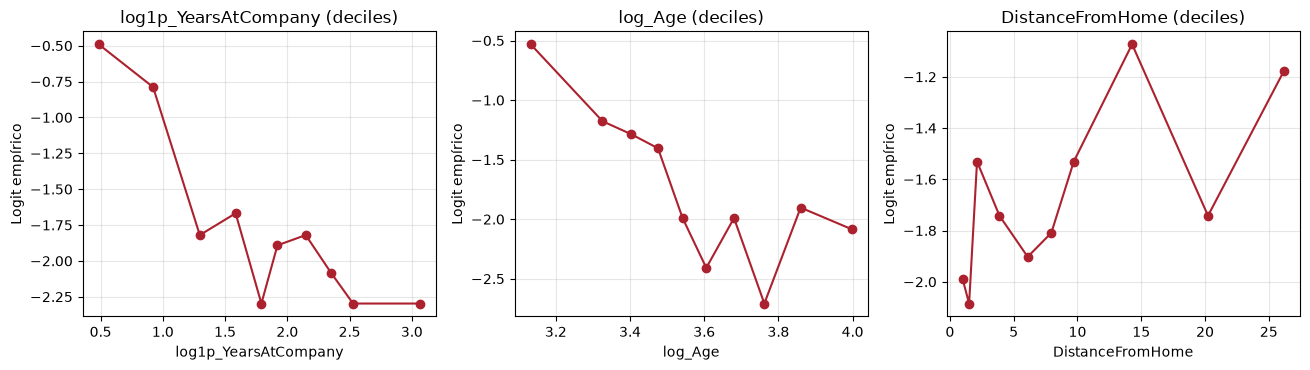

In [30]:
linealidad_final = pruebas_linealidad(VARIABLES_FINALES, X_final, train_imp, y_train)
linealidad_final.to_csv(RESULTADOS / "lenin_diagnostico_linealidad.csv", index=False)
display(linealidad_final.round(4))

continuas_finales = [v for v in VARIABLES_FINALES if base_original(v) in CONTINUAS]
fig, axes = plt.subplots(1, len(continuas_finales), figsize=(4.4 * len(continuas_finales), 3.8))
for eje, variable in zip(np.atleast_1d(axes), continuas_finales):
    x = valores_base(train_imp, variable)
    grupos = pd.qcut(x.rank(method="first"), q=10, labels=False)
    tabla = pd.DataFrame({"x": x, "y": y_train}).groupby(grupos).agg(
        x=("x", "mean"), s=("y", "sum"), n=("y", "size"))
    eje.plot(tabla["x"], np.log((tabla["s"] + 0.5) / (tabla["n"] - tabla["s"] + 0.5)),
             "o-", color="#AC212E")
    eje.set(xlabel=variable, ylabel="Logit empírico", title=f"{variable} (deciles)")
    eje.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURAS / "lenin_diagnostico_linealidad.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

Tras la corrección, ln(Age) (p = 0,30) y DistanceFromHome (p = 0,96) no
muestran curvatura, y JobSatisfaction lineal se mantiene (p = 0,65). En
ln(1 + YearsAtCompany) queda una curvatura leve (p = 0,034), mucho menor que la
del modelo lineal (estadístico 2,12 frente a 4,87). Se acepta como
aproximación: un *spline* agregaría parámetros para una mejora probablemente
pequeña.

### 14.3 Residuos

En regresión logística la respuesta es 0/1, por lo que los residuos crudos
forman dos bandas y no se espera normalidad. Se usan:

- **Residuos agrupados:** se ordenan las observaciones por probabilidad
  ajustada, se forman ≈ $\sqrt{n}$ grupos y se grafica el residuo medio
  ($\bar y - \bar p$) con bandas $\pm 2\sqrt{\bar p(1-\bar p)/n_g}$. Con buena
  calibración, cerca del 95 % de los puntos queda dentro.
- **Residuos de desvianza** frente al predictor lineal.
- **Hosmer-Lemeshow** (10 grupos, 8 gl), solo como complemento.

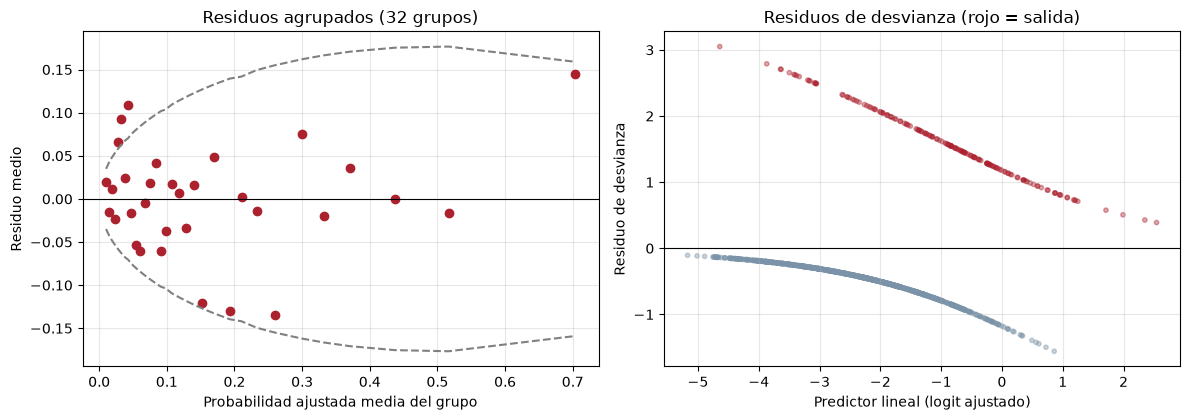

,Indicador,Valor
0,Grupos de residuos,32.0000
1,Grupos fuera de banda,3.0000
2,Hosmer-Lemeshow (8 gl),12.9591
3,Valor p Hosmer-Lemeshow,0.1133
4,Residuos de desvianza |r| > 2,41.0000


In [31]:
p_sp = resultado_final_sp.predict(X_final)
eta_sp = np.log(p_sp / (1 - p_sp))
residuo_desvianza = np.sign(y_train - p_sp) * np.sqrt(
    -2 * (y_train * np.log(p_sp) + (1 - y_train) * np.log(1 - p_sp)))

n_grupos = int(np.sqrt(len(y_train)))
grupos = pd.qcut(p_sp.rank(method="first"), q=n_grupos, labels=False)
agrupados = pd.DataFrame({"p": p_sp, "y": y_train, "g": grupos}).groupby("g").agg(
    p=("p", "mean"), y=("y", "mean"), n=("y", "size"))
agrupados["residuo"] = agrupados["y"] - agrupados["p"]
agrupados["banda"] = 2 * np.sqrt(agrupados["p"] * (1 - agrupados["p"]) / agrupados["n"])
fuera_banda = int((agrupados["residuo"].abs() > agrupados["banda"]).sum())

deciles = pd.qcut(p_sp.rank(method="first"), q=10, labels=False)
hl_tabla = pd.DataFrame({"p": p_sp, "y": y_train, "g": deciles}).groupby("g").agg(
    observados=("y", "sum"), esperados=("p", "sum"), n=("y", "size"))
hl = (((hl_tabla["observados"] - hl_tabla["esperados"]) ** 2)
      / (hl_tabla["esperados"] * (1 - hl_tabla["esperados"] / hl_tabla["n"]))).sum()
p_hl = stats.chi2.sf(hl, 8)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
axes[0].plot(agrupados["p"], agrupados["residuo"], "o", color="#AC212E")
axes[0].plot(agrupados["p"], agrupados["banda"], "--", color="gray")
axes[0].plot(agrupados["p"], -agrupados["banda"], "--", color="gray")
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set(xlabel="Probabilidad ajustada media del grupo", ylabel="Residuo medio",
            title=f"Residuos agrupados ({n_grupos} grupos)")
axes[1].scatter(eta_sp, residuo_desvianza, s=10, alpha=0.4,
                c=np.where(y_train == 1, "#AC212E", "#7A93A8"))
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set(xlabel="Predictor lineal (logit ajustado)", ylabel="Residuo de desvianza",
            title="Residuos de desvianza (rojo = salida)")
for eje in axes:
    eje.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURAS / "lenin_diagnostico_residuos.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

diagnostico_residuos = pd.DataFrame({
    "Indicador": ["Grupos de residuos", "Grupos fuera de banda", "Hosmer-Lemeshow (8 gl)",
                  "Valor p Hosmer-Lemeshow", "Residuos de desvianza |r| > 2"],
    "Valor": [n_grupos, fuera_banda, hl, p_hl, int((np.abs(residuo_desvianza) > 2).sum())],
})
diagnostico_residuos.to_csv(RESULTADOS / "lenin_diagnostico_residuos.csv", index=False)
display(diagnostico_residuos.round(4))

En el gráfico de residuos agrupados, 3 de 32 grupos (9 %) quedan fuera de las
bandas, frente a unos 1,6 esperados (5 %). Están en probabilidades bajas e
intermedias (0,04 a 0,26) y tienen signos distintos, sin un patrón sistemático.
Hosmer-Lemeshow no rechaza el ajuste (12,96 con 8 gl, p = 0,11).

Los residuos de desvianza forman las dos bandas esperables en una respuesta
binaria. Los 41 residuos con |r| > 2 (4,0 %) corresponden a salidas que el
modelo consideraba poco probables; ningún empleado que permanece supera ese
valor.

### 14.4 Observaciones influyentes

Para cada empleado se calcula el apalancamiento $h_{ii}$ (diagonal de la
matriz sombrero: cuán atípica es su combinación de predictores) y la distancia
de Cook (cuánto cambian los coeficientes al omitirlo). Umbrales orientativos:
$4/n$ para Cook y $2k/n$ para el apalancamiento, con $k$ parámetros.

Se reajusta el modelo sin los 10 empleados más influyentes para medir cuánto
cambian los OR, y se cruza la lista con los 10 empleados más influyentes del
jackknife de S2 (diferencia de ingresos).

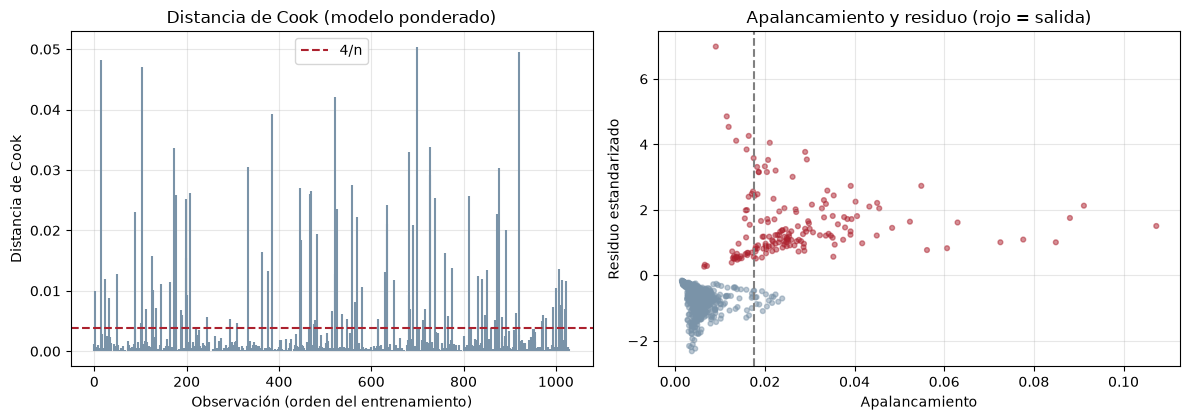

Cook > 4/n (0.0039): 94 ponderado | 82 sin ponderar
Apalancamiento > 2k/n (0.0175): 145
Salidas entre los 10 más influyentes: 10
Con ingreso imputado entre los 10: 1
Coincidencias con los 10 más influyentes de S2: [825]


,Cook,Apalancamiento,Residuo estandarizado,Cook sin ponderar,Attrition,OverTime,YearsAtCompany,JobSatisfaction,Age,DistanceFromHome,JobLevel,Department,MonthlyIncome
EmployeeNumber,,,,,,,,,,,,,
1747,0.050,0.091,2.127,0.017,Yes,No,4,4,30,8,1,Human Resources,2180.000
1127,0.050,0.009,6.987,0.012,Yes,No,18,4,39,2,4,Research & Development,12169.000
1907,0.048,0.055,2.733,0.014,Yes,No,4,4,56,24,1,Research & Development,2587.000
825,0.047,0.029,3.769,0.013,Yes,Yes,31,2,58,2,5,Research & Development,19246.000
1101,0.042,0.029,3.538,0.011,Yes,No,13,3,33,29,2,Research & Development,4508.000
842,0.039,0.021,4.049,0.011,Yes,No,9,4,55,2,2,Sales,5160.000
1420,0.034,0.039,2.732,0.010,Yes,No,4,1,49,28,2,Research & Development,4284.000
1459,0.034,0.016,4.258,0.009,Yes,No,10,2,31,1,3,Research & Development,7446.000
1467,0.033,0.088,1.752,0.014,Yes,No,2,3,34,9,1,Human Resources,2742.000


,OR completo,OR sin 10 influyentes,IC95 OR completo inferior,IC95 OR completo superior,Cambio relativo (%),Dentro del IC completo
const,0.201,0.132,0.124,0.326,-34.477,True
OverTime,3.895,5.080,2.614,5.806,30.401,True
log1p_YearsAtCompany,0.726,0.663,0.586,0.900,-8.774,True
JobSatisfaction,0.739,0.697,0.612,0.891,-5.666,True
log_Age,0.763,0.681,0.612,0.951,-10.759,True
DistanceFromHome,1.273,1.274,1.053,1.538,0.087,True
ind_JobLevel_1,2.996,3.357,1.803,4.977,12.044,True
Dept_Human Resources,1.402,1.051,0.666,2.952,-25.044,True
Dept_Sales,3.326,4.363,2.049,5.399,31.172,True


In [32]:
def influencia_glm(resultado_glm):
    info = resultado_glm.get_influence()
    return pd.DataFrame({
        "Apalancamiento": info.hat_matrix_diag,
        "Cook": info.cooks_distance[0],
        "Residuo estandarizado": info.resid_studentized,
    }, index=y_train.index)


glm_sp = sm.GLM(y_train, X_final, family=sm.families.Binomial()).fit()
glm_pond = sm.GLM(y_train, X_final, family=sm.families.Binomial(),
                  var_weights=y_train.map(pesos_train).to_numpy()).fit()
np.testing.assert_allclose(glm_pond.params, resultado_final.params, rtol=1e-6)

influencia = influencia_glm(glm_pond).join(influencia_glm(glm_sp).add_suffix(" sin ponderar"))
influencia["Attrition"] = train_mcar["Attrition"]
influencia["Ingreso imputado"] = train_mcar["MonthlyIncome"].isna()
influencia.sort_values("Cook", ascending=False).to_csv(
    RESULTADOS / "lenin_influencia_observaciones.csv", index_label="EmployeeNumber")

n_obs, k_par = X_final.shape
umbral_cook, umbral_hat = 4 / n_obs, 2 * k_par / n_obs
columnas_originales = ["OverTime", "YearsAtCompany", "JobSatisfaction", "Age",
                       "DistanceFromHome", "JobLevel", "Department", "MonthlyIncome"]
top_influyentes = influencia.sort_values("Cook", ascending=False).head(10)[
    ["Cook", "Apalancamiento", "Residuo estandarizado", "Cook sin ponderar", "Attrition"]
].join(train_imp[columnas_originales])

jackknife_s2 = pd.read_csv(DIRECTORIO_S2 / "resultados" / "rodrigo_jackknife_influencia.csv",
                           index_col="EmployeeNumber")
top_s2 = jackknife_s2["cambio_absoluto_diferencia"].nlargest(10).index
coinciden_s2 = sorted(set(top_s2) & set(top_influyentes.index))

ids_sin = y_train.index.difference(top_influyentes.index)
resultado_sin = ajustar_logit(X_final.loc[ids_sin], y_train.loc[ids_sin], pesos_final)
sensibilidad = pd.DataFrame({
    "OR completo": np.exp(resultado_final.params),
    "OR sin 10 influyentes": np.exp(resultado_sin.params),
    "IC95 OR completo inferior": coef_final["IC95 OR inferior"],
    "IC95 OR completo superior": coef_final["IC95 OR superior"],
})
sensibilidad["Cambio relativo (%)"] = (
    sensibilidad["OR sin 10 influyentes"] / sensibilidad["OR completo"] - 1) * 100
sensibilidad["Dentro del IC completo"] = sensibilidad["OR sin 10 influyentes"].between(
    sensibilidad["IC95 OR completo inferior"], sensibilidad["IC95 OR completo superior"])
sensibilidad.to_csv(RESULTADOS / "lenin_sensibilidad_influyentes.csv", index_label="Termino")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
axes[0].stem(np.arange(n_obs), influencia["Cook"], linefmt="#7A93A8", markerfmt=" ", basefmt=" ")
axes[0].axhline(umbral_cook, color="#AC212E", linestyle="--", label="4/n")
axes[0].set(xlabel="Observación (orden del entrenamiento)", ylabel="Distancia de Cook",
            title="Distancia de Cook (modelo ponderado)")
axes[0].legend()
axes[1].scatter(influencia["Apalancamiento"], influencia["Residuo estandarizado"], s=12,
                alpha=0.5, c=np.where(y_train == 1, "#AC212E", "#7A93A8"))
axes[1].axvline(umbral_hat, color="gray", linestyle="--")
axes[1].set(xlabel="Apalancamiento", ylabel="Residuo estandarizado",
            title="Apalancamiento y residuo (rojo = salida)")
for eje in axes:
    eje.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURAS / "lenin_diagnostico_influencia.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Cook > 4/n ({umbral_cook:.4f}): {(influencia['Cook'] > umbral_cook).sum()} ponderado"
      f" | {(influencia['Cook sin ponderar'] > umbral_cook).sum()} sin ponderar")
print(f"Apalancamiento > 2k/n ({umbral_hat:.4f}): {(influencia['Apalancamiento'] > umbral_hat).sum()}")
print("Salidas entre los 10 más influyentes:", int((top_influyentes["Attrition"] == "Yes").sum()))
print("Con ingreso imputado entre los 10:", int(influencia.loc[top_influyentes.index, "Ingreso imputado"].sum()))
print("Coincidencias con los 10 más influyentes de S2:", coinciden_s2 or "ninguna")
display(top_influyentes.round(3))
display(sensibilidad.round(3))

En el modelo ponderado, 94 empleados superan $4/n$ en Cook (82 sin ponderar).
Con $n = 1.029$ ese umbral es muy bajo; la distancia máxima es 0,050, lejos de
los valores 0,5 o 1 que suelen asociarse a una influencia seria.

Los 10 más influyentes son salidas. Es esperable: cada salida pesa 5,2 veces una
permanencia, y estos casos son **salidas poco previstas** por el modelo. Por
ejemplo, el empleado 825 (58 años, 31 en la empresa, nivel 5, ingreso 19.246) o
el 1127 (nivel 4, 18 años en la empresa). Solo uno de los 10 tenía el ingreso
imputado. El 825 también estaba entre los empleados más influyentes del
jackknife de S2, que destacó salidas con ingresos altos.

Al retirar conjuntamente los 10 empleados seleccionados, los OR
conservan su dirección y quedan dentro de los intervalos del 95 %
del ajuste completo. Sin embargo, algunos cambios son apreciables:
OverTime aumenta aproximadamente un 30 %, Sales un 31 % y Human
Resources disminuye un 25 %.

Este análisis evidencia sensibilidad a ese conjunto de observaciones;
no demuestra que ningún empleado influya individualmente ni constituye
una prueba formal de estabilidad. Se conservan todos los registros
porque no se identificaron errores que justificaran su eliminación.
La exclusión se utiliza únicamente como escenario de sensibilidad.

## 15. Parámetros, configuración y probabilidades de prueba

Se guardan:

- `lenin_parametros_transformacion.json`: coeficientes de la imputación,
  medias y desviaciones de estandarización, codificaciones y pesos.
- `lenin_parametros_escalado.csv`: la misma estandarización en tabla.
- `lenin_configuracion_modelo_final.json`: variables, ponderación, umbral,
  modelo seleccionado, criterio de selección y resultados de validación.
- `lenin_probabilidades_prueba.csv`: probabilidades del modelo final en
  prueba. La prueba se imputa y estandariza con parámetros de entrenamiento y
  **su variable Attrition no se usa en este notebook**.

In [33]:
parametros_transformacion = {
    "imputacion": imputador_final.parametros(),
    "estandarizacion": {
        v: {"media": preparador_final.medias_[v], "desviacion": preparador_final.desviaciones_[v]}
        for v in preparador_final.numericas
    },
    "codificacion_OverTime": {"No": 0, "Yes": 1},
    "codificacion_Department": {
        "referencia": "Research & Development",
        "indicadoras": columnas_de(["Department"]) if "Department" in VARIABLES_FINALES else [],
    },
    "codificacion_objetivo": config_s3["codificacion_objetivo"],
    "pesos_entrenamiento": {str(k): v for k, v in pesos_train.items()},
    "ajustado_con": "Entrenamiento completo (1.029 registros); ingresos observados para la imputación",
}
(RESULTADOS / "lenin_parametros_transformacion.json").write_text(
    json.dumps(parametros_transformacion, ensure_ascii=False, indent=2), encoding="utf-8")
preparador_final.parametros().to_csv(RESULTADOS / "lenin_parametros_escalado.csv", index=False)

fila_elegida = comparacion_fijas.query(
    "Modelo == @MODELO_FINAL and Ponderacion == 'Ponderado'").iloc[0]

configuracion_final = {
    "responsable": "Lenin Morales",
    "modelo_seleccionado": MODELO_FINAL,
    "descripcion": {
        "M1": "Base F2: OverTime, MonthlyIncome, YearsAtCompany, JobSatisfaction",
        "M2": "Stepwise bidireccional por AIC (sin ponderar)",
        "M3": "Mejor subconjunto por BIC (sin ponderar)",
        "M2c": ("Variables de M2 (stepwise AIC) con forma funcional corregida: "
                "ln(1+YearsAtCompany), ln(Age) e indicador JobLevel = 1"),
    }[MODELO_FINAL],
    "modelo_preliminar": {"modelo": MODELO_PRELIMINAR, "variables": VARIABLES_PRELIMINARES},
    "transformaciones": {
        "log1p_X": "ln(1 + X)", "log_X": "ln(X)", "ind_X_k": "1 si X == k",
        "estandarizacion": "z con media y DE (ddof=1) del entrenamiento; no se aplica a OverTime, Department ni ind_*",
    },
    "variables": VARIABLES_FINALES,
    "columnas_diseno": list(X_final.columns),
    "variables_candidatas": CANDIDATAS,
    "especificaciones": ESPECIFICACIONES,
    "ponderacion": PONDERACION_FINAL,
    "pesos_entrenamiento": {str(k): v for k, v in pesos_train.items()},
    "formula_pesos": "n / (2 * n_clase), recalculados en cada pliegue",
    "covarianza": "HC0 (sandwich)" if PONDERACION_FINAL == "balanceada" else "clasica",
    "umbral": UMBRAL,
    "objetivo": config_s3["objetivo"],
    "codificacion_objetivo": config_s3["codificacion_objetivo"],
    "imputacion": {
        "estrategia": config_s3["estrategia_principal"],
        "variable": config_s3["variable_imputada"],
        "predictores": config_s3["predictores_imputacion"],
    },
    "datos_MCAR": config_s3["datos_MCAR"],
    "particion": config_s3["particion"],
    "semilla": SEMILLA,
    "validacion": {
        "esquema": "RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)",
        "dentro_de_cada_pliegue": ["imputacion", "estandarizacion", "seleccion", "pesos"],
        "regla": ("recall >= 0.5; AUC y F1 a <= 1 EE del mejor; menor numero de parametros. "
                  "Forma funcional: M2c si no empeora AUC ni F1 ponderados y reduce AIC"),
        "metricas_de": "S3/resultados/lenin_validacion_m2_vs_m2c.csv (especificacion fija, ponderado)",
        "AUC_media": float(fila_elegida["AUC media"]),
        "Recall_media": float(fila_elegida["Recall media"]),
        "Precision_media": float(fila_elegida["Precision media"]),
        "F1_media": float(fila_elegida["F1 media"]),
    },
    "prueba_usada_en_seleccion": False,
    "codigo_reajuste": "S3/src/lenin_modelado.py :: reajustar_modelo_final(RAIZ)",
    "archivos": {
        "coeficientes": "S3/resultados/lenin_coeficientes_modelo_final.csv",
        "parametros_transformacion": "S3/resultados/lenin_parametros_transformacion.json",
        "validacion": "S3/resultados/lenin_validacion_comparacion.csv",
        "validacion_m2_vs_m2c": "S3/resultados/lenin_validacion_m2_vs_m2c.csv",
        "probabilidades_prueba": "S3/resultados/lenin_probabilidades_prueba.csv",
    },
}
(RESULTADOS / "lenin_configuracion_modelo_final.json").write_text(
    json.dumps(configuracion_final, ensure_ascii=False, indent=2), encoding="utf-8")

# Probabilidades de prueba con parámetros de entrenamiento.
test_imp = imputador_final.transformar(test_mcar)
regresion_test = pd.read_csv(DIRECTORIO_S3 / "datos" / "regresion_test.csv",
                             index_col="EmployeeNumber")
np.testing.assert_allclose(test_imp.loc[regresion_test.index, "MonthlyIncome"],
                           regresion_test["MonthlyIncome"])
X_test_final = preparador_final.transformar(test_imp)
assert list(X_test_final.columns) == list(X_final.columns)

probabilidades_prueba = pd.DataFrame({
    "Probabilidad_salida": resultado_final.predict(X_test_final),
    "Probabilidad_salida_sin_ponderar": resultado_final_sp.predict(X_test_final),
}, index=X_test_final.index)
probabilidades_prueba["Clasificacion_umbral"] = (
    probabilidades_prueba["Probabilidad_salida"] >= UMBRAL).astype(int)
probabilidades_prueba.index.name = "EmployeeNumber"
assert probabilidades_prueba["Probabilidad_salida"].between(0, 1).all()
probabilidades_prueba.to_csv(RESULTADOS / "lenin_probabilidades_prueba.csv")

print(json.dumps({k: configuracion_final[k] for k in
                  ["modelo_seleccionado", "variables", "ponderacion", "umbral"]},
                 ensure_ascii=False, indent=2))
print("Probabilidades de prueba guardadas:", len(probabilidades_prueba))

{
  "modelo_seleccionado": "M2c",
  "variables": [
    "OverTime",
    "log1p_YearsAtCompany",
    "JobSatisfaction",
    "log_Age",
    "DistanceFromHome",
    "ind_JobLevel_1",
    "Department"
  ],
  "ponderacion": "balanceada",
  "umbral": 0.5
}
Probabilidades de prueba guardadas: 441


## 16. Verificación de reproducibilidad

`reajustar_modelo_final` lee solo la configuración guardada y los datos de F2,
repite imputación, estandarización y pesos, y ajusta el modelo. Debe entregar
exactamente los mismos coeficientes que se guardaron.

In [34]:
resultado_reajuste, preparador_reajuste, imputador_reajuste, _ = reajustar_modelo_final(RAIZ)
coef_guardados = pd.read_csv(RESULTADOS / "lenin_coeficientes_modelo_final.csv",
                             index_col="Termino")

np.testing.assert_allclose(resultado_reajuste.params, coef_guardados["Coeficiente"], rtol=1e-8)
np.testing.assert_allclose(resultado_reajuste.bse, coef_guardados["Error estandar"], rtol=1e-6)
np.testing.assert_allclose(
    resultado_reajuste.predict(preparador_reajuste.transformar(imputador_reajuste.transformar(test_mcar))),
    probabilidades_prueba["Probabilidad_salida"], rtol=1e-8)

archivos_lenin = sorted(p.name for p in RESULTADOS.glob("lenin_*")) + sorted(
    p.name for p in FIGURAS.glob("lenin_*"))
print("Modelo final reajustado desde la configuración: coeficientes y probabilidades idénticos.")
print(f"Archivos generados ({len(archivos_lenin)}):")
for nombre in archivos_lenin:
    print(" -", nombre)

Modelo final reajustado desde la configuración: coeficientes y probabilidades idénticos.
Archivos generados (32):
 - lenin_coeficientes_modelo_final.csv
 - lenin_coeficientes_modelo_final_sin_ponderar.csv
 - lenin_coeficientes_modelos.csv
 - lenin_comparacion_ajuste_sin_ponderar.csv
 - lenin_comparacion_forma_funcional.csv
 - lenin_configuracion_modelo_final.json
 - lenin_diagnostico_linealidad.csv
 - lenin_diagnostico_residuos.csv
 - lenin_estabilidad_seleccion.csv
 - lenin_influencia_observaciones.csv
 - lenin_interpretacion_or_modelo_final.csv
 - lenin_linealidad_preliminar.csv
 - lenin_parametros_escalado.csv
 - lenin_parametros_transformacion.json
 - lenin_probabilidades_prueba.csv
 - lenin_seleccion_por_pliegue.csv
 - lenin_sensibilidad_influyentes.csv
 - lenin_stepwise_aic_traza.csv
 - lenin_subconjuntos_aic_bic.csv
 - lenin_validacion_comparacion.csv
 - lenin_validacion_diferencias_pareadas.csv
 - lenin_validacion_m2_vs_m2c.csv
 - lenin_validacion_m2_vs_m2c_pliegues.csv
 - leni

## 17. Síntesis y limitaciones

Se propone M2c ponderado, una variante de M2 que modifica la forma
funcional de edad, antigüedad y nivel laboral tras los diagnósticos.

Incluye OverTime, ln(1 + YearsAtCompany), JobSatisfaction, ln(Age),
DistanceFromHome, el indicador JobLevel = 1 y Department. Tiene nueve
parámetros, incluyendo intercepto e indicadoras de departamento.
Utiliza pesos balanceados de 0,596 y 3,099, covarianza HC0 y umbral 0,5.

### Resultados de validación interna

La comparación exploratoria de especificaciones fijas obtuvo AUC
de 0,777, recall de 0,707, precision de 0,329 y F1 de 0,449.
La ponderación mejoró la detección de salidas con el umbral utilizado,
a cambio de más falsas alarmas.

M1, M2 y M3 permiten comparar el modelo fundamentado en S1/S2,
la selección stepwise por AIC y la reducción por BIC. M2c complementa
esa comparación como variante motivada por los diagnósticos.

### Alcance y limitaciones

- Las variables y transformaciones de M2c se eligieron utilizando todo
  el entrenamiento. Su validación interna puede ser optimista y no
  evalúa independientemente todo el proceso de selección.
- Los valores p e intervalos son condicionales a la especificación;
  no incorporan toda la incertidumbre de selección y transformación.
- La sensibilidad a los casos influyentes requiere cautela, aunque los
  coeficientes conservaron su dirección en el escenario examinado.
- Las puntuaciones ponderadas sirven para clasificación. La versión
  sin ponderar tampoco garantiza probabilidades calibradas.
- El conjunto de prueba no intervino en las decisiones de S3, pero ya
  fue examinado en F2. Su evaluación tiene un alcance exploratorio.
- Los datos son sintéticos y las asociaciones no implican causalidad.

### Comparación de estrategias de imputación

M2c no incluye MonthlyIncome. Como mediana y regresión conservan las
mismas filas y los otros predictores, ambas producirán el mismo ajuste
de M2c. La eliminación puede cambiarlo porque modifica las observaciones
disponibles para entrenamiento.

Rodrigo deberá realizar la comparación solicitada para M2c y
complementarla con M1, que sí incluye ingreso. Esto permitirá examinar
la sensibilidad directa de los coeficientes y del desempeño a la
estrategia de imputación.

### Archivos para la validación

Las probabilidades de prueba están en lenin_probabilidades_prueba.csv.
La especificación y los parámetros se documentan en
lenin_configuracion_modelo_final.json. El modelo puede reconstruirse
mediante reajustar_modelo_final(RAIZ).

# Parte 3. Evaluación y estabilidad


## 1: Importación de Librerías y Carga de Datos

In [35]:
from pathlib import Path
import json
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from threadpoolctl import threadpool_limits

limite_hilos = threadpool_limits(limits=1)

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
)

# Localizar el repositorio.
RAIZ = next(
    (
        carpeta
        for carpeta in [Path.cwd(), *Path.cwd().parents]
        if (
            carpeta / "datos" / "WA_Fn-UseC_-HR-Employee-Attrition.csv"
        ).is_file()
    ),
    None,
)

if RAIZ is None:
    raise FileNotFoundError("No se encontró la raíz del repositorio.")

DIRECTORIO_S3 = RAIZ / "S3"
RESULTADOS = DIRECTORIO_S3 / "resultados"
FIGURAS = DIRECTORIO_S3 / "figuras"

RESULTADOS.mkdir(parents=True, exist_ok=True)
FIGURAS.mkdir(parents=True, exist_ok=True)

# Reutilizar exactamente los procedimientos de Lenin.
sys.path.insert(0, str(DIRECTORIO_S3 / "src"))

from lenin_modelado import (
    ImputadorRegresion,
    PreparadorDiseno,
    ajustar_logit,
    codificar_objetivo,
    pesos_balanceados,
    reajustar_modelo_final,
    tabla_coeficientes,
)

config_final = json.loads(
    (RESULTADOS / "lenin_configuracion_modelo_final.json")
    .read_text(encoding="utf-8")
)

SEMILLA = config_final["semilla"]
UMBRAL = config_final["umbral"]
ESPECIFICACIONES = config_final["especificaciones"]
MODELO_FINAL = config_final["modelo_seleccionado"]

df_mcar = pd.read_csv(
    RAIZ / config_final["datos_MCAR"]
).set_index("EmployeeNumber")

particion = pd.read_csv(
    RAIZ / config_final["particion"]
).set_index("EmployeeNumber")

train_mcar = df_mcar.loc[
    particion.index[particion["Conjunto"] == "Entrenamiento"]
].copy()

test_mcar = df_mcar.loc[
    particion.index[particion["Conjunto"] == "Prueba"]
].copy()

y_train = codificar_objetivo(train_mcar["Attrition"])
y_test = codificar_objetivo(test_mcar["Attrition"])

assert len(train_mcar) == 1029
assert len(test_mcar) == 441
assert set(train_mcar.index).isdisjoint(test_mcar.index)

print("Modelo final seleccionado por Lenin:", MODELO_FINAL)
print("Entrenamiento:", len(train_mcar))
print("Prueba:", len(test_mcar))

display(pd.DataFrame([
    {
        "Modelo": nombre,
        "Predictores": ", ".join(variables),
    }
    for nombre, variables in ESPECIFICACIONES.items()
]))

Modelo final seleccionado por Lenin: M2c
Entrenamiento: 1029
Prueba: 441


,Modelo,Predictores
0,M1,"OverTime, MonthlyIncome, YearsAtCompany, JobSatisfaction"
1,M2,"OverTime, YearsAtCompany, JobSatisfaction, Age, DistanceFromHome, JobLevel, Department"
2,M3,"OverTime, YearsAtCompany, JobSatisfaction, Age, Department"
3,M2c,"OverTime, log1p_YearsAtCompany, JobSatisfaction, log_Age, DistanceFromHome, ind_JobLev..."


## 2 (Punto 1): Evaluación de los Modelos en Entrenamiento y Prueba

In [36]:
def calcular_metricas(y_real, probabilidades):
    predicciones = (np.asarray(probabilidades) >= UMBRAL).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_real, predicciones, labels=[0, 1]
    ).ravel()

    return {
        "Registros": len(y_real),
        "Accuracy": accuracy_score(y_real, predicciones),
        "Precision": precision_score(
            y_real, predicciones, zero_division=0
        ),
        "Recall": recall_score(
            y_real, predicciones, zero_division=0
        ),
        "F1": f1_score(y_real, predicciones, zero_division=0),
        "AUC": roc_auc_score(y_real, probabilidades),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
    }


# Ajustar la imputación solo con entrenamiento.
imputador = ImputadorRegresion(
    config_final["imputacion"]["variable"],
    config_final["imputacion"]["predictores"],
).ajustar(train_mcar)

train_imp = imputador.transformar(train_mcar)
test_imp = imputador.transformar(test_mcar)

pesos_train = pesos_balanceados(y_train)

ajustes = {}
predicciones_modelos = {}
filas_metricas = []
tablas_coeficientes = []

for nombre, variables in ESPECIFICACIONES.items():
    preparador = PreparadorDiseno(variables).ajustar(train_imp)
    X_train = preparador.transformar(train_imp)
    X_test = preparador.transformar(test_imp)

    for ponderacion, pesos in [
        ("Sin ponderar", None),
        ("Ponderado", pesos_train),
    ]:
        resultado = ajustar_logit(X_train, y_train, pesos)

        clave = (nombre, ponderacion)
        ajustes[clave] = {
            "resultado": resultado,
            "preparador": preparador,
        }

        tabla = tabla_coeficientes(resultado).reset_index()
        tabla.insert(0, "Ponderacion", ponderacion)
        tabla.insert(0, "Modelo", nombre)
        tablas_coeficientes.append(tabla)

        for conjunto, X, y in [
            ("Entrenamiento", X_train, y_train),
            ("Prueba", X_test, y_test),
        ]:
            probabilidades = resultado.predict(X)

            assert X.index.equals(y.index)
            assert np.isfinite(probabilidades).all()
            assert probabilidades.between(0, 1).all()

            predicciones_modelos[
                (nombre, ponderacion, conjunto)
            ] = probabilidades

            filas_metricas.append({
                "Modelo": nombre,
                "Ponderacion": ponderacion,
                "Conjunto": conjunto,
                **calcular_metricas(y, probabilidades),
            })

metricas_modelos = pd.DataFrame(filas_metricas)

metricas_modelos.to_csv(
    RESULTADOS / "rodrigo_metricas_modelos.csv",
    index=False,
)

pd.concat(tablas_coeficientes, ignore_index=True).to_csv(
    RESULTADOS / "rodrigo_coeficientes_modelos.csv",
    index=False,
)

# Comprobar que reproducimos las probabilidades finales de Lenin.
probabilidades_lenin = pd.read_csv(
    RESULTADOS / "lenin_probabilidades_prueba.csv",
    index_col="EmployeeNumber",
)

np.testing.assert_allclose(
    predicciones_modelos[
        (MODELO_FINAL, "Ponderado", "Prueba")
    ].loc[probabilidades_lenin.index],
    probabilidades_lenin["Probabilidad_salida"],
    rtol=1e-7,
    atol=1e-10,
)

display(
    metricas_modelos.loc[
        (metricas_modelos["Conjunto"] == "Prueba")
        & (metricas_modelos["Ponderacion"] == "Ponderado")
    ].round(4)
)

print("Probabilidades del modelo final coinciden con las de Lenin.")

,Modelo,Ponderacion,Conjunto,Registros,Accuracy,Precision,Recall,F1,AUC,TN,FP,FN,TP
3,M1,Ponderado,Prueba,441,0.7302,0.3421,0.7324,0.4664,0.7734,270,100,19,52
7,M2,Ponderado,Prueba,441,0.7234,0.3311,0.7042,0.4505,0.7614,269,101,21,50
11,M3,Ponderado,Prueba,441,0.7234,0.3241,0.6620,0.4352,0.7463,272,98,24,47
15,M2c,Ponderado,Prueba,441,0.7506,0.3636,0.7324,0.4860,0.7722,279,91,19,52


Probabilidades del modelo final coinciden con las de Lenin.


## Matrices de confusión y curvas ROC

Se muestran los modelos ponderados con umbral 0,5. Las matrices de
confusión distinguen salidas detectadas, salidas omitidas y falsas
alarmas, tanto en entrenamiento como en prueba.

Las curvas ROC comparan la capacidad de discriminación a través de
distintos umbrales. La evaluación de prueba se utiliza para describir
el desempeño de las especificaciones previamente seleccionadas.

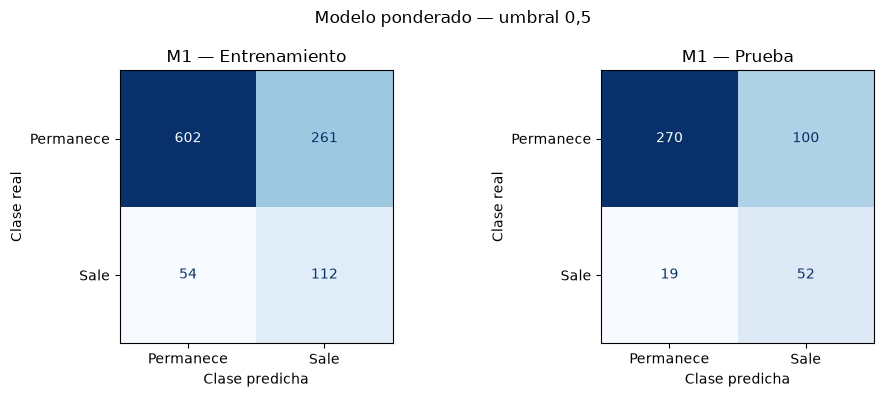

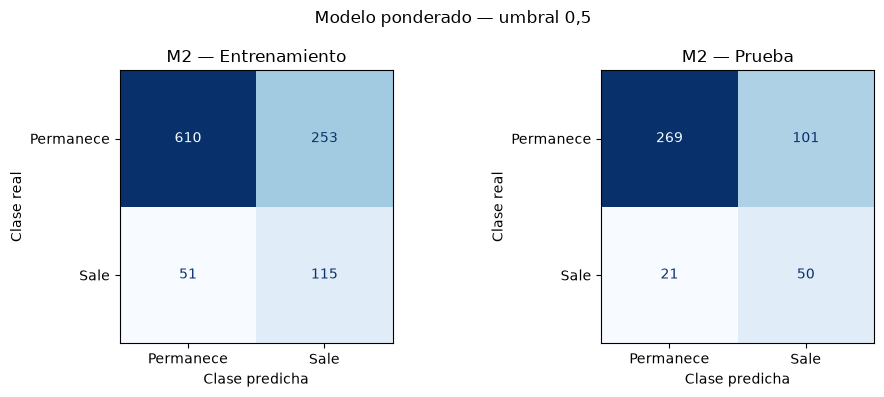

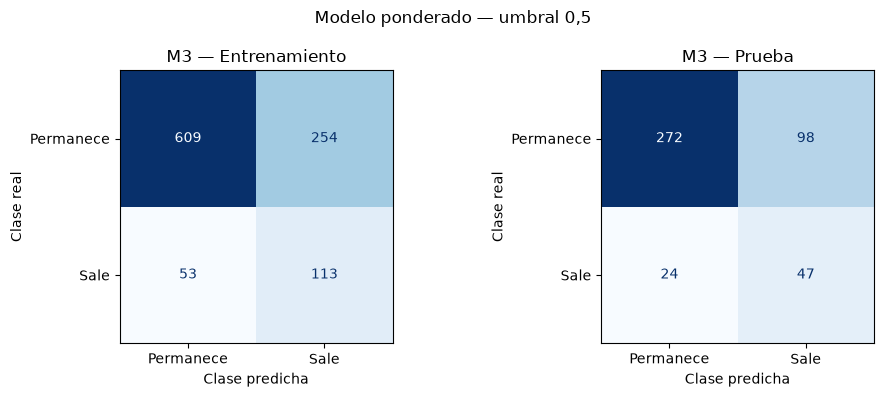

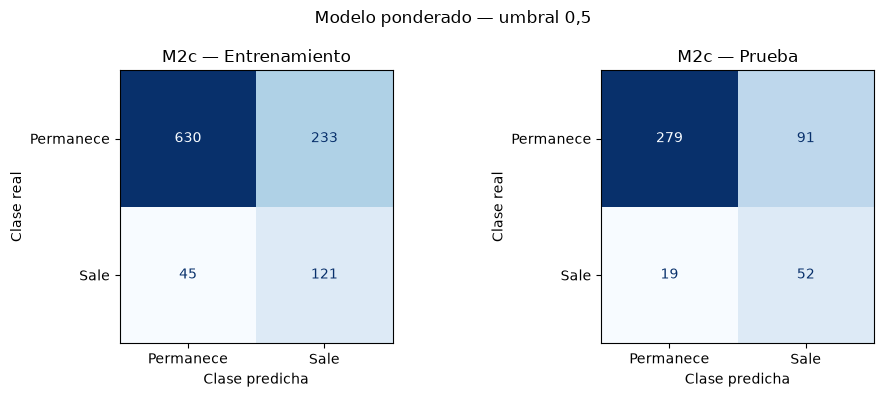

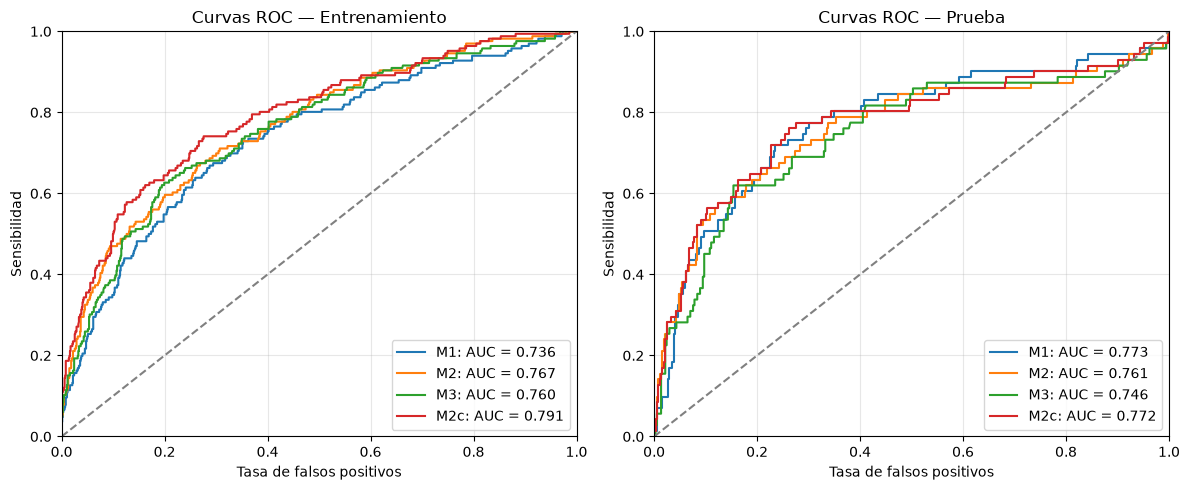

Matrices de confusión y curvas ROC guardadas.


In [37]:
from sklearn.metrics import ConfusionMatrixDisplay

# Un gráfico por modelo, con entrenamiento y prueba.
for nombre in ESPECIFICACIONES:
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    for ax, conjunto, y in [
        (axes[0], "Entrenamiento", y_train),
        (axes[1], "Prueba", y_test),
    ]:
        probabilidades = predicciones_modelos[
            (nombre, "Ponderado", conjunto)
        ]
        predicciones = (probabilidades >= UMBRAL).astype(int)

        ConfusionMatrixDisplay.from_predictions(
            y,
            predicciones,
            labels=[0, 1],
            display_labels=["Permanece", "Sale"],
            cmap="Blues",
            colorbar=False,
            ax=ax,
        )

        ax.set_title(f"{nombre} — {conjunto}")
        ax.set_xlabel("Clase predicha")
        ax.set_ylabel("Clase real")

    fig.suptitle("Modelo ponderado — umbral 0,5")
    fig.tight_layout()

    fig.savefig(
        FIGURAS / f"rodrigo_confusion_{nombre}.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

# Comparación ROC de los cuatro modelos.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, conjunto, y in [
    (axes[0], "Entrenamiento", y_train),
    (axes[1], "Prueba", y_test),
]:
    for nombre in ESPECIFICACIONES:
        probabilidades = predicciones_modelos[
            (nombre, "Ponderado", conjunto)
        ]

        fpr, tpr, _ = roc_curve(y, probabilidades)
        area = roc_auc_score(y, probabilidades)

        ax.plot(
            fpr, tpr,
            label=f"{nombre}: AUC = {area:.3f}",
        )

    ax.plot([0, 1], [0, 1], "--", color="gray")
    ax.set(
        xlabel="Tasa de falsos positivos",
        ylabel="Sensibilidad",
        title=f"Curvas ROC — {conjunto}",
        xlim=(0, 1),
        ylim=(0, 1),
    )
    ax.legend()
    ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(
    FIGURAS / "rodrigo_roc_modelos.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

print("Matrices de confusión y curvas ROC guardadas.")

## 3: Comparación con la Referencia de F2

In [38]:
probabilidades_f2 = pd.read_csv(
    RAIZ / "Formativa2" / "resultados" / "probabilidades_prueba.csv",
    index_col="EmployeeNumber",
)

assert probabilidades_f2.index.is_unique
assert set(probabilidades_f2.index) == set(y_test.index)

comparacion_f2 = pd.DataFrame([
    {
        "Modelo": "F2: sin ponderar",
        **calcular_metricas(
            y_test,
            probabilidades_f2.loc[y_test.index, "Probabilidad_salida"],
        ),
    },
    {
        "Modelo": "S3 M2c: sin ponderar",
        **calcular_metricas(
            y_test,
            predicciones_modelos[
                (MODELO_FINAL, "Sin ponderar", "Prueba")
            ],
        ),
    },
    {
        "Modelo": "S3 M2c: ponderado",
        **calcular_metricas(
            y_test,
            predicciones_modelos[
                (MODELO_FINAL, "Ponderado", "Prueba")
            ],
        ),
    },
])

comparacion_f2.to_csv(
    RESULTADOS / "rodrigo_comparacion_F2_S3.csv",
    index=False,
)

display(comparacion_f2.round(4))

diferencia_recall = (
    comparacion_f2.iloc[2]["Recall"]
    - comparacion_f2.iloc[0]["Recall"]
) * 100

print(
    f"Variación de recall frente a F2: "
    f"{diferencia_recall:.2f} puntos porcentuales."
)

,Modelo,Registros,Accuracy,Precision,Recall,F1,AUC,TN,FP,FN,TP
0,F2: sin ponderar,441,0.8435,0.6667,0.0563,0.1039,0.7724,368,2,67,4
1,S3 M2c: sin ponderar,441,0.8549,0.6296,0.2394,0.3469,0.7728,360,10,54,17
2,S3 M2c: ponderado,441,0.7506,0.3636,0.7324,0.4860,0.7722,279,91,19,52


Variación de recall frente a F2: 67.61 puntos porcentuales.


### Interpretación de la comparación

El modelo M2c ponderado detecta 52 de las 71 salidas de prueba,
frente a cuatro detectadas por el modelo de F2. El recall aumenta
de 5,63 % a 73,24 %, mientras las falsas alarmas pasan de dos a 91.

La precision disminuye de 66,67 % a 36,36 % y la accuracy de 84,35 %
a 75,06 %. El F1 aumenta de 0,1039 a 0,4860. Por tanto, la mejora
de detección tiene como costo una mayor cantidad de empleados que
permanecen clasificados como salida.

El AUC es prácticamente igual: 0,7724 en F2 y 0,7722 en M2c ponderado.
La mejora de recall con umbral 0,5 no implica una mejora equivalente
de discriminación global.

La comparación entre F2 y S3 combina cambios de especificación,
imputación y ponderación. Para examinar específicamente la ponderación,
se comparan también las dos versiones de M2c sobre los mismos datos.

Estos resultados son exploratorios y no justifican decisiones reales
de personal con este conjunto sintético.

In [39]:
VARIABLES_BOOT = config_final["variables"]

ajuste_referencia = ajustes[(MODELO_FINAL, "Ponderado")]
resultado_referencia = ajuste_referencia["resultado"]
preparador_referencia = ajuste_referencia["preparador"]

TERMINOS_BOOT = list(resultado_referencia.params.index)


def ajustar_remuestra(datos):
    y = codificar_objetivo(datos["Attrition"])

    if y.nunique() != 2:
        raise ValueError("La remuestra no contiene ambas clases.")

    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always")

        imputador_b = ImputadorRegresion(
            config_final["imputacion"]["variable"],
            config_final["imputacion"]["predictores"],
        ).ajustar(datos)

        datos_imp = imputador_b.transformar(datos)
        preparador_b = PreparadorDiseno(VARIABLES_BOOT).ajustar(datos_imp)
        X_b = preparador_b.transformar(datos_imp)

        resultado_b = ajustar_logit(X_b, y, pesos_balanceados(y))

    mensajes = [
        f"{aviso.category.__name__}: {aviso.message}"
        for aviso in avisos
    ]

    if not resultado_b.converged:
        raise RuntimeError("El ajuste no convergió.")

    if any(
        "converg" in mensaje.lower() or "separation" in mensaje.lower()
        for mensaje in mensajes
    ):
        raise RuntimeError(" | ".join(mensajes))

    coeficientes = resultado_b.params.copy()
    intercepto = float(coeficientes["const"])

    for variable in preparador_b.numericas:
        beta = float(resultado_b.params[variable])
        media_b = preparador_b.medias_[variable]
        de_b = preparador_b.desviaciones_[variable]
        media_ref = preparador_referencia.medias_[variable]
        de_ref = preparador_referencia.desviaciones_[variable]

        coeficientes[variable] = beta * de_ref / de_b
        intercepto += beta * (media_ref - media_b) / de_b

    coeficientes["const"] = intercepto
    coeficientes = coeficientes.reindex(TERMINOS_BOOT)

    if not np.isfinite(coeficientes.to_numpy()).all():
        raise ValueError("Coeficientes no finitos.")

    return coeficientes, mensajes

## 4. Bootstrap del modelo final

Se generan 10.000 remuestras con reemplazo del entrenamiento MCAR.
La especificación de M2c se mantiene fija, por lo que el análisis
es condicional a las variables y transformaciones seleccionadas.

En cada remuestra se reajustan la imputación, la estandarización,
los pesos balanceados y la regresión logística. Se registran
advertencias y fallos de ajuste.

Los coeficientes se expresan en la escala estandarizada del
entrenamiento original, ajustando también el intercepto. Así,
los intervalos comparan efectos definidos en una misma unidad.

El ingreso no aparece en M2c; su imputación se repite para conservar
el procedimiento, aunque no modifica directamente sus predicciones.

In [40]:
import subprocess

ruta_ejecutor = (
    DIRECTORIO_S3 / "src" / "rodrigo_ejecutar_bootstrap.py"
)

if not ruta_ejecutor.is_file():
    raise FileNotFoundError("Falta el ejecutor bootstrap por procesos.")

subprocess.run(
    [sys.executable, str(ruta_ejecutor)],
    cwd=RAIZ,
    check=True,
)

print("Bootstrap completado mediante procesos independientes.")

Los 10.000 intentos están guardados.
Bootstrap completado mediante procesos independientes.


## 5: Intervalos de Confianza al 95%, Odds Ratios y Signos

In [41]:
import hashlib

# Recuperar el modelo y su escala de referencia.
resultado_referencia, preparador_referencia, _, _ = (
    reajustar_modelo_final(RAIZ)
)

TERMINOS_BOOT = list(resultado_referencia.params.index)

contenido_control = (
    train_mcar.to_csv()
    + json.dumps(config_final, sort_keys=True)
    + resultado_referencia.params.to_json()
    + preparador_referencia.parametros().to_csv(index=False)
    + "bootstrap_por_replica_v1"
)

huella_esperada = hashlib.sha256(
    contenido_control.encode("utf-8")
).hexdigest()

# Cargar los lotes guardados.
carpeta_lotes = RESULTADOS / "rodrigo_bootstrap_lotes"
registros = []

for archivo in sorted(carpeta_lotes.glob("lote_*.json")):
    lote = json.loads(archivo.read_text(encoding="utf-8"))

    assert lote["huella"] == huella_esperada, (
        "Un lote no corresponde a la configuración actual."
    )

    registros.extend(lote["registros"])

registros.sort(key=lambda r: r["Replica"])

assert [r["Replica"] for r in registros] == list(range(1, 10001)), (
    "Faltan intentos o existen duplicados."
)

registro_bootstrap = pd.DataFrame([
    {
        "Replica": r["Replica"],
        "Estado": r["Estado"],
        "Detalle": r["Detalle"],
    }
    for r in registros
])

replicas_bootstrap = pd.DataFrame([
    {"Replica": r["Replica"], **r["Coeficientes"]}
    for r in registros
    if r["Estado"] == "Valida"
])

assert not replicas_bootstrap.empty

coeficientes_boot = replicas_bootstrap[
    TERMINOS_BOOT
].to_numpy(dtype=float)

assert np.isfinite(coeficientes_boot).all()

limite_inferior, limite_superior = np.percentile(
    coeficientes_boot, [2.5, 97.5], axis=0
)

coef_originales = resultado_referencia.params.to_numpy()
ic_tradicional = np.asarray(resultado_referencia.conf_int())

tabla_bootstrap = pd.DataFrame({
    "Termino": TERMINOS_BOOT,
    "Coeficiente original": coef_originales,
    "Media bootstrap": coeficientes_boot.mean(axis=0),
    "Error estandar bootstrap": coeficientes_boot.std(axis=0, ddof=1),
    "IC95 HC0 inferior": ic_tradicional[:, 0],
    "IC95 HC0 superior": ic_tradicional[:, 1],
    "IC95 bootstrap inferior": limite_inferior,
    "IC95 bootstrap superior": limite_superior,
    "OR original": np.exp(coef_originales),
    "IC95 OR HC0 inferior": np.exp(ic_tradicional[:, 0]),
    "IC95 OR HC0 superior": np.exp(ic_tradicional[:, 1]),
    "IC95 OR bootstrap inferior": np.exp(limite_inferior),
    "IC95 OR bootstrap superior": np.exp(limite_superior),
    "Proporcion conserva signo": (
        np.sign(coeficientes_boot) == np.sign(coef_originales)
    ).mean(axis=0),
    "IC bootstrap incluye cero": (
        (limite_inferior <= 0) & (limite_superior >= 0)
    ),
})

registro_bootstrap.to_csv(
    RESULTADOS / "rodrigo_bootstrap_registro.csv", index=False
)

replicas_bootstrap.to_csv(
    RESULTADOS / "rodrigo_bootstrap_coeficientes.csv", index=False
)

tabla_bootstrap.to_csv(
    RESULTADOS / "rodrigo_bootstrap_intervalos.csv", index=False
)

print("Intentos verificados:", len(registro_bootstrap))
print("Réplicas válidas:", len(replicas_bootstrap))
print(
    "Intentos fallidos:",
    registro_bootstrap["Estado"].eq("Fallida").sum(),
)

display(tabla_bootstrap[[
    "Termino",
    "Coeficiente original",
    "IC95 bootstrap inferior",
    "IC95 bootstrap superior",
    "Proporcion conserva signo",
    "IC bootstrap incluye cero",
]].round(4))

Intentos verificados: 10000
Réplicas válidas: 10000
Intentos fallidos: 0


,Termino,Coeficiente original,IC95 bootstrap inferior,IC95 bootstrap superior,Proporcion conserva signo,IC bootstrap incluye cero
0,const,-1.6034,-2.1536,-1.2178,1.0000,False
1,OverTime,1.3598,0.9798,1.8006,1.0000,False
2,log1p_YearsAtCompany,-0.3196,-0.5501,-0.1032,0.9977,False
3,JobSatisfaction,-0.3029,-0.5056,-0.1206,0.9990,False
4,log_Age,-0.2709,-0.5093,-0.0530,0.9937,False
5,DistanceFromHome,0.2411,0.0483,0.4360,0.9920,False
6,ind_JobLevel_1,1.0972,0.5995,1.6480,1.0000,False
7,Dept_Human Resources,0.3381,-0.5791,1.0431,0.7839,True
8,Dept_Sales,1.2018,0.7307,1.7298,1.0000,False


### Interpretación de la estabilidad bootstrap

Se obtuvieron 10.000 réplicas válidas. Los coeficientes se expresan
en la escala del entrenamiento original para que sus intervalos
sean comparables.

Los intervalos percentiles del 95 % excluyen cero para horas extra,
antigüedad transformada, satisfacción, edad transformada, distancia,
nivel laboral de entrada y departamento Sales. Estos predictores
conservan su signo en al menos el 99,20 % de las réplicas.

Human Resources presenta un intervalo que incluye cero
[−0,5791; 1,0431] y conserva el signo positivo en el 78,39 % de
las réplicas. Su dirección requiere mayor cautela.

La estabilidad es condicional a las variables y transformaciones
seleccionadas. El bootstrap no incorpora todo el proceso de selección,
no establece causalidad y no demuestra validez externa.

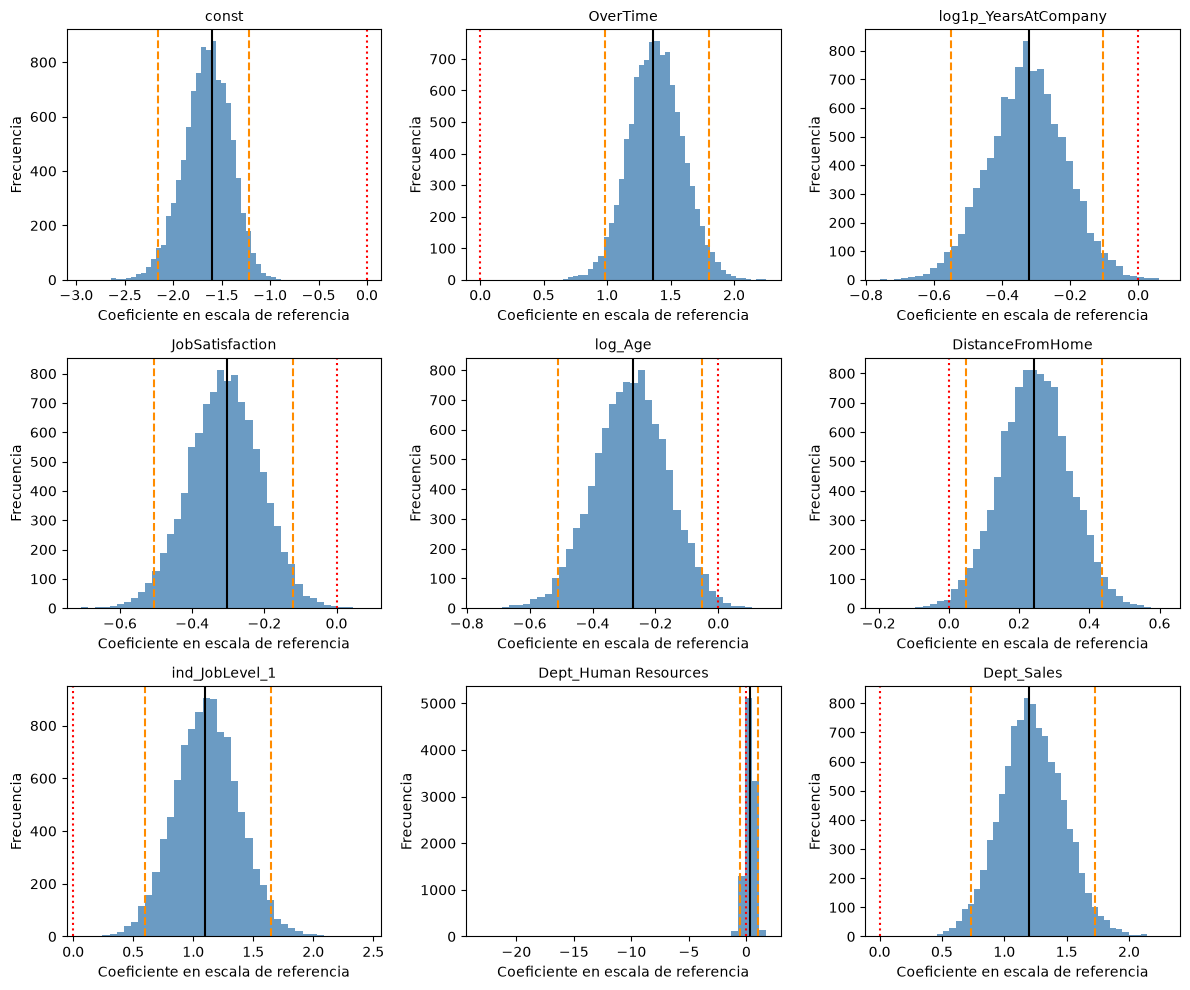

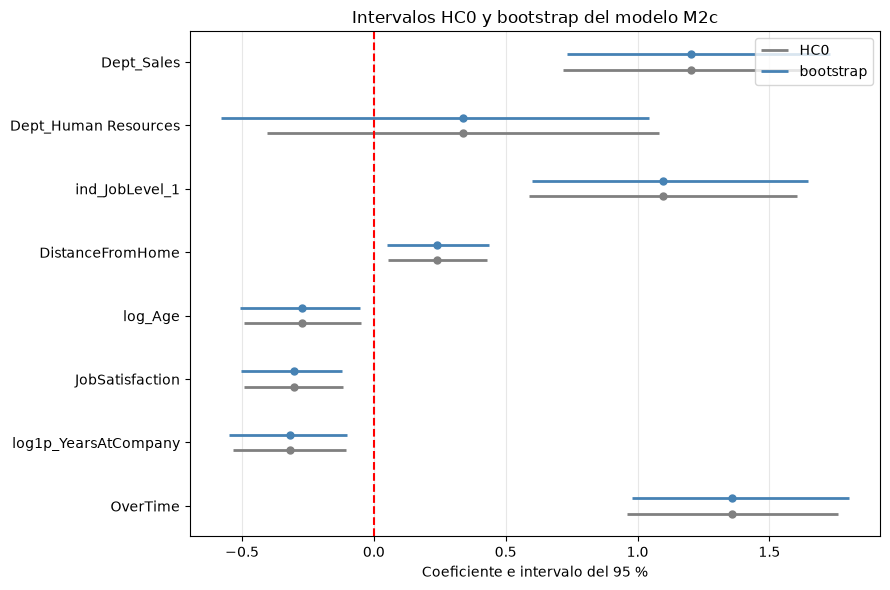

In [42]:
# Distribuciones bootstrap.
fig, axes = plt.subplots(3, 3, figsize=(12, 10))

for ax, termino in zip(axes.flat, TERMINOS_BOOT):
    valores = replicas_bootstrap[termino]
    original = resultado_referencia.params[termino]
    inferior, superior = np.percentile(valores, [2.5, 97.5])

    ax.hist(valores, bins=40, color="steelblue", alpha=0.8)
    ax.axvline(original, color="black", label="Original")
    ax.axvline(0, color="red", linestyle=":")
    ax.axvline(inferior, color="darkorange", linestyle="--")
    ax.axvline(superior, color="darkorange", linestyle="--")
    ax.set_title(termino, fontsize=10)
    ax.set_xlabel("Coeficiente en escala de referencia")
    ax.set_ylabel("Frecuencia")

fig.tight_layout()
fig.savefig(
    FIGURAS / "rodrigo_bootstrap_distribuciones.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

# Comparación de intervalos HC0 y bootstrap, sin intercepto.
tabla_grafico = tabla_bootstrap.loc[
    tabla_bootstrap["Termino"] != "const"
].reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9, 6))
posiciones = np.arange(len(tabla_grafico))

for desplazamiento, metodo, color in [
    (-0.12, "HC0", "gray"),
    (0.12, "bootstrap", "steelblue"),
]:
    inferior = tabla_grafico[f"IC95 {metodo} inferior"].to_numpy()
    superior = tabla_grafico[f"IC95 {metodo} superior"].to_numpy()
    y = posiciones + desplazamiento

    ax.hlines(
        y, inferior, superior,
        color=color, linewidth=2, label=metodo,
    )
    ax.scatter(
        tabla_grafico["Coeficiente original"],
        y,
        color=color,
        s=25,
    )

ax.axvline(0, color="red", linestyle="--")
ax.set_yticks(posiciones, tabla_grafico["Termino"])
ax.set_xlabel("Coeficiente e intervalo del 95 %")
ax.set_title("Intervalos HC0 y bootstrap del modelo M2c")
ax.legend()
ax.grid(axis="x", alpha=0.3)

fig.tight_layout()
fig.savefig(
    FIGURAS / "rodrigo_bootstrap_comparacion_intervalos.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

## 6: Comparación entre M1, M2c y las estrategias de imputación

In [43]:
ESTRATEGIAS = ["eliminacion", "mediana", "regresion"]

datasets = {
    estrategia: {
        conjunto: pd.read_csv(
            DIRECTORIO_S3 / "datos" / f"{estrategia}_{conjunto}.csv",
            index_col="EmployeeNumber",
        )
        for conjunto in ["train", "test"]
    }
    for estrategia in ESTRATEGIAS
}

ids_comunes = datasets["eliminacion"]["test"].index
assert len(ids_comunes) == 390

for estrategia in ESTRATEGIAS:
    assert datasets[estrategia]["train"].index.is_unique
    assert datasets[estrategia]["test"].index.is_unique
    assert set(ids_comunes) <= set(datasets[estrategia]["test"].index)

assert len(datasets["eliminacion"]["train"]) == 933
assert len(datasets["mediana"]["train"]) == 1029
assert len(datasets["regresion"]["train"]) == 1029

modelos_sensibilidad = {
    "M1": ESPECIFICACIONES["M1"],
    MODELO_FINAL: config_final["variables"],
}

ajustes_sensibilidad = {}
filas_sensibilidad = []
predicciones_sensibilidad = []

for nombre, variables in modelos_sensibilidad.items():
    for estrategia, conjuntos in datasets.items():
        entrenamiento = conjuntos["train"]
        prueba = conjuntos["test"]

        y_ajuste = codificar_objetivo(entrenamiento["Attrition"])

        # Ajustar escalado y pesos con el entrenamiento de cada estrategia.
        preparador = PreparadorDiseno(variables).ajustar(entrenamiento)
        X_ajuste = preparador.transformar(entrenamiento)

        resultado = ajustar_logit(
            X_ajuste,
            y_ajuste,
            pesos_balanceados(y_ajuste),
        )

        ajustes_sensibilidad[(nombre, estrategia)] = {
            "resultado": resultado,
            "preparador": preparador,
        }

        for etiqueta, datos in [
            ("Entrenamiento", entrenamiento),
            ("Prueba disponible", prueba),
            ("Prueba comun", prueba.loc[ids_comunes]),
        ]:
            X = preparador.transformar(datos)
            y = codificar_objetivo(datos["Attrition"])
            probabilidades = resultado.predict(X)

            filas_sensibilidad.append({
                "Modelo": nombre,
                "Estrategia": estrategia,
                "Conjunto": etiqueta,
                "N entrenamiento": len(entrenamiento),
                **calcular_metricas(y, probabilidades),
            })

            if etiqueta == "Prueba disponible":
                predicciones_sensibilidad.append(pd.DataFrame({
                    "EmployeeNumber": datos.index,
                    "Modelo": nombre,
                    "Estrategia": estrategia,
                    "Attrition": y.to_numpy(),
                    "Probabilidad_salida": probabilidades.to_numpy(),
                }))

sensibilidad_imputacion = pd.DataFrame(filas_sensibilidad)

sensibilidad_imputacion.to_csv(
    RESULTADOS / "rodrigo_sensibilidad_imputacion_metricas.csv",
    index=False,
)

pd.concat(predicciones_sensibilidad, ignore_index=True).to_csv(
    RESULTADOS / "rodrigo_sensibilidad_imputacion_predicciones.csv",
    index=False,
)

# M2c excluye ingreso: mediana y regresión deben dar el mismo ajuste.
np.testing.assert_allclose(
    ajustes_sensibilidad[(MODELO_FINAL, "mediana")]["resultado"].params,
    ajustes_sensibilidad[(MODELO_FINAL, "regresion")]["resultado"].params,
    rtol=1e-7,
    atol=1e-10,
)

display(
    sensibilidad_imputacion.loc[
        sensibilidad_imputacion["Conjunto"] == "Prueba comun",
        [
            "Modelo", "Estrategia", "N entrenamiento",
            "Registros", "Accuracy", "Precision", "Recall", "F1", "AUC",
        ],
    ].round(4)
)

print("Subconjunto común identificado por EmployeeNumber:", len(ids_comunes))

,Modelo,Estrategia,N entrenamiento,Registros,Accuracy,Precision,Recall,F1,AUC
2,M1,eliminacion,933,390,0.7359,0.3623,0.7692,0.4926,0.8027
5,M1,mediana,1029,390,0.7256,0.3521,0.7692,0.4831,0.8036
8,M1,regresion,1029,390,0.7333,0.3597,0.7692,0.4902,0.8034
11,M2c,eliminacion,933,390,0.7462,0.3672,0.7231,0.4870,0.7963
14,M2c,mediana,1029,390,0.7564,0.3828,0.7538,0.5078,0.8017
17,M2c,regresion,1029,390,0.7564,0.3828,0.7538,0.5078,0.8017


Subconjunto común identificado por EmployeeNumber: 390


### Comparación de coeficientes e intervalos

Los coeficientes de cada estrategia se convierten a una escala común:
la media y desviación estándar del entrenamiento imputado por regresión.
También se transforma el intercepto y la matriz de covarianza HC0.

Así, las diferencias de coeficientes y odds ratios no se confunden
con cambios en la unidad de estandarización. Los intervalos son
condicionales a cada ajuste y no incorporan toda la incertidumbre
de imputación ni de selección.

In [44]:
filas_coeficientes = []
filas_escalas = []

for nombre, variables in modelos_sensibilidad.items():
    referencia = PreparadorDiseno(variables).ajustar(
        datasets["regresion"]["train"]
    )

    escala = referencia.parametros()
    escala.insert(0, "Modelo", nombre)
    filas_escalas.append(escala)

    for estrategia in ESTRATEGIAS:
        ajuste = ajustes_sensibilidad[(nombre, estrategia)]
        resultado = ajuste["resultado"]
        preparador = ajuste["preparador"]

        terminos = list(resultado.params.index)
        transformacion = np.eye(len(terminos))

        for variable in preparador.numericas:
            j = terminos.index(variable)
            de = preparador.desviaciones_[variable]

            transformacion[j, j] = (
                referencia.desviaciones_[variable] / de
            )
            transformacion[0, j] = (
                referencia.medias_[variable]
                - preparador.medias_[variable]
            ) / de

        beta = transformacion @ resultado.params.to_numpy()

        covarianza = (
            transformacion
            @ np.asarray(resultado.cov_params())
            @ transformacion.T
        )

        errores = np.sqrt(np.diag(covarianza))
        inferior = beta - 1.959963984540054 * errores
        superior = beta + 1.959963984540054 * errores

        for j, termino in enumerate(terminos):
            filas_coeficientes.append({
                "Modelo": nombre,
                "Estrategia": estrategia,
                "Termino": termino,
                "Coeficiente": beta[j],
                "Error estandar HC0": errores[j],
                "IC95 inferior": inferior[j],
                "IC95 superior": superior[j],
                "OR": np.exp(beta[j]),
                "IC95 OR inferior": np.exp(inferior[j]),
                "IC95 OR superior": np.exp(superior[j]),
            })

coeficientes_sensibilidad = pd.DataFrame(filas_coeficientes)

coeficientes_sensibilidad.to_csv(
    RESULTADOS / "rodrigo_sensibilidad_imputacion_coeficientes.csv",
    index=False,
)

pd.concat(filas_escalas, ignore_index=True).to_csv(
    RESULTADOS / "rodrigo_sensibilidad_escala_referencia.csv",
    index=False,
)

display(
    coeficientes_sensibilidad.loc[
        coeficientes_sensibilidad["Termino"] == "MonthlyIncome"
    ].round(4)
)

print("Coeficientes e intervalos guardados en una escala común.")

,Modelo,Estrategia,Termino,Coeficiente,Error estandar HC0,IC95 inferior,IC95 superior,OR,IC95 OR inferior,IC95 OR superior
2,M1,eliminacion,MonthlyIncome,-0.4129,0.1102,-0.6289,-0.1969,0.6617,0.5332,0.8213
7,M1,mediana,MonthlyIncome,-0.3983,0.1105,-0.6149,-0.1818,0.6714,0.5407,0.8338
12,M1,regresion,MonthlyIncome,-0.3769,0.1087,-0.5898,-0.1639,0.6860,0.5544,0.8488


Coeficientes e intervalos guardados en una escala común.


### Interpretación del impacto de la imputación

En M1, el ingreso mantiene una asociación negativa ajustada con la
salida bajo las tres estrategias. Los OR, expresados en una escala
común, son 0,662 con eliminación, 0,671 con mediana y 0,686 con
regresión. Los tres intervalos HC0 del 95 % excluyen 1.

En los 390 empleados comunes de prueba, el AUC de M1 varía entre
0,8027 y 0,8036. Estos resultados muestran poca sensibilidad del
desempeño y conservación de la dirección del ingreso en los escenarios
examinados; no demuestran equivalencia formal entre estrategias.

En M2c, mediana y regresión producen resultados idénticos porque el
ingreso no forma parte de su especificación y ambas conservan las
mismas filas. La eliminación modifica el conjunto de entrenamiento,
por lo que puede cambiar el ajuste incluso sin incluir ingreso.

Se mantiene regresión como estrategia principal por la evidencia
predictiva de imputación obtenida en entrenamiento. La evaluación
de prueba se utiliza para describir sensibilidad, no para cambiar
retroactivamente esa elección.

Los resultados del subconjunto común no deben compararse directamente
con los del conjunto completo de 441 empleados, porque cambia la
composición de la muestra evaluada.

# Parte 4. Conclusiones integradas

S1 identificó asociaciones entre salida, horas extra, ingreso,
antigüedad y satisfacción. S2 respaldó la dirección de las diferencias
de ingreso y examinó correlaciones y sensibilidad a valores extremos.
Estos hallazgos fundamentaron la preparación y los modelos de S3.

La regresión se mantuvo como imputación principal por su menor error
en entrenamiento y la conservación de registros. Frente a mediana,
redujo el MAE y el RMSE de validación cruzada aproximadamente 34,3 %
y 39,7 %. Sin embargo, la imputación determinista redujo dispersión
y reforzó algunas correlaciones; no reconstruye toda la incertidumbre
de los ingresos faltantes.

Se construyeron M1, M2 por stepwise AIC y M3 reducido por BIC.
Tras los diagnósticos se propuso M2c ponderado. Su elección se
fundamentó en entrenamiento y no se modificó según prueba.
Las transformaciones elegidas con todo el entrenamiento pueden
hacer optimista su validación interna.

En los 441 empleados de prueba, M2c detectó 52 de 71 salidas y produjo
91 falsas alarmas: recall 73,24 %, precision 36,36 %, F1 0,4860,
accuracy 75,06 % y AUC 0,7722. Frente a F2 mejora la detección con
umbral 0,5, con más falsas alarmas; el AUC permanece prácticamente igual.
La comparación F2–S3 combina cambios de especificación y ponderación.

Las 10.000 réplicas bootstrap válidas muestran conservación del signo
en al menos el 99,20 % para los predictores salvo Human Resources.
Su intervalo incluye cero y conserva signo positivo en el 78,39 %.
La estabilidad es condicional a la especificación seleccionada.

M2c no incluye ingreso, por lo que mediana y regresión producen el
mismo ajuste sobre las mismas filas. La comparación complementaria
con M1 conserva la dirección negativa del ingreso y muestra AUC
similares entre estrategias en los 390 empleados comunes.
Esto no demuestra equivalencia formal entre métodos.

Se recomienda validar el flujo con datos reales independientes,
examinar calibración y definir umbrales según costos de los errores.
La prueba ya fue examinada en F2, las inferencias no incorporan toda
la selección y los datos son sintéticos; el alcance es académico
y exploratorio.
